# B final system: weight-2 joint intent and slot model

This B training/evaluation notebook includes source, training, best-checkpoint reload, Dev/Test scores and error analysis. The group integrates both stages and the final report/chat record.

The recipe and representative seed 42 were selected using Dev before this system's Test evaluation. The earlier weight-1 system's Test result had already been observed; that chronology is retained. No settings are changed based on this final Test score. Only raw `utt` enters inference. All model/source code is embedded below.

Presentation labels were edited after execution. Numerical outputs are unchanged. The original executed version is retained at commit `8c845be0149a88b7a84c80f286fd2b0382e16101`. Published source checksums describe the edited snapshot; previously displayed checksums refer to the original execution.

In [1]:
import importlib.util, subprocess, sys
packages = {"torch": "torch==2.9.1", "numpy": "numpy>=1.26,<3",
            "matplotlib": "matplotlib>=3.8,<4"}
missing = [spec for module, spec in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
import torch, numpy
print("Python:", sys.version)
print("PyTorch:", torch.__version__, "NumPy:", numpy.__version__)


Python: 3.12.14 (main, Aug 25 2026, 13:50:33) [Clang 22.1.3 ]
PyTorch: 2.9.1 NumPy: 2.5.4


## Embedded source and tests

The complete source snapshot is stored in readable cells below.

In [2]:
import json, os, tempfile, hashlib
from pathlib import Path
RESOURCE_ROOT = Path.cwd().resolve()
WORK = Path(tempfile.mkdtemp(prefix='sc4002-b-notebook-'))
SOURCE_FILES = json.loads("[\"src/data/annotations.py\", \"src/data/labels.py\", \"src/data/loader.py\", \"src/evaluation/metrics.py\", \"src/model/__init__.py\", \"src/model/artifacts.py\", \"src/model/crf.py\", \"src/model/data.py\", \"src/model/evaluate.py\", \"src/model/model.py\", \"src/model/predict.py\", \"src/model/tokenization.py\", \"src/model/train.py\", \"tests/test_annotations.py\", \"tests/test_artifacts.py\", \"tests/test_integration.py\", \"tests/test_labels.py\", \"tests/test_metrics.py\", \"tests/test_model.py\", \"scripts/audit_model.py\", \"scripts/check_a_integration.py\", \"scripts/check_label_inventory.py\", \"scripts/compare_pooling.py\", \"scripts/compare_runs.py\", \"scripts/compare_slot_weight.py\", \"scripts/finalize_b.py\", \"scripts/inspect_annotations.py\", \"scripts/inspect_labels.py\", \"scripts/plot_b_results.py\", \"scripts/prepare_glove.py\", \"scripts/summarize_b_followup.py\", \"scripts/verify_b_notebook.py\", \"src/__init__.py\", \"scripts/__init__.py\"]")
for relative in SOURCE_FILES:
    (WORK / relative).parent.mkdir(parents=True, exist_ok=True)
for name in list(sys.modules):
    if name == 'src' or name.startswith('src.') or name == 'scripts' or name.startswith('scripts.'):
        del sys.modules[name]
sys.path.insert(0, str(WORK))
print('Embedded files:', len(SOURCE_FILES))


Embedded files: 34


### `src/data/annotations.py`

In [3]:
%%writefile {WORK}/src/data/annotations.py
"""Parse MASSIVE 1.0 annot_utt into candidate Python-character spans.

The output span convention [start, end) is provisional until agreed with B.
No normalization is performed: reconstructed text must equal the raw utt.
"""

import re

# MASSIVE's documented annotation form: [slot_type : slot_text]
_SLOT = re.compile(
    r"\[(?P<type>[A-Za-z_][A-Za-z0-9_]*) : (?P<text>[^\[\]]+)\]"
)


def extract_slots(utt: str, annot_utt: str) -> list[dict]:
    """Return slots with character offsets into the original utt.

    Raises ValueError if the annotated text cannot reconstruct utt exactly.
    Offsets use Python string indices.
    """
    if not isinstance(utt, str) or not isinstance(annot_utt, str):
        raise TypeError("utt and annot_utt must be strings")

    parts = []
    slots = []
    cursor = 0
    position = 0

    for match in _SLOT.finditer(annot_utt):
        plain_text = annot_utt[cursor:match.start()]
        parts.append(plain_text)
        position += len(plain_text)

        slot_text = match.group("text")
        start = position
        end = start + len(slot_text)

        slots.append({
            "type": match.group("type"),
            "start": start,
            "end": end,
            "text": slot_text,
        })

        parts.append(slot_text)
        position = end
        cursor = match.end()

    parts.append(annot_utt[cursor:])
    reconstructed = "".join(parts)

    if reconstructed != utt:
        raise ValueError(
            "Annotation cannot be reconstructed exactly as utt: "
            f"utt={utt!r}, reconstructed={reconstructed!r}"
        )

    # Validate offsets without searching by text.
    for slot in slots:
        if utt[slot["start"]:slot["end"]] != slot["text"]:
            raise ValueError(f"Slot offset mismatch: {slot!r}")

    return slots


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/data/annotations.py


### `src/data/labels.py`

In [4]:
%%writefile {WORK}/src/data/labels.py
"""Train-only MASSIVE label statistics and ID mappings."""

from collections import Counter
from collections.abc import Iterable

from src.data.annotations import extract_slots


def count_train_labels(
    train_records: Iterable[dict],
) -> tuple[Counter, Counter]:
    """Count intents per utterance and slot types per span."""
    intent_counts = Counter()
    slot_counts = Counter()

    for index, record in enumerate(train_records):
        if record["partition"] != "train":
            raise ValueError(
                f"Record {index} is not in Train"
            )

        intent = record["intent"]
        if not isinstance(intent, str) or not intent:
            raise ValueError(
                f"Record {index} has invalid intent: {intent!r}"
            )

        slots = extract_slots(
            record["utt"],
            record["annot_utt"],
        )

        intent_counts[intent] += 1
        slot_counts.update(slot["type"] for slot in slots)

    return intent_counts, slot_counts


def build_label_maps(
    labels: Iterable[str],
) -> tuple[dict[str, int], dict[int, str]]:
    """Build reproducible, alphabetically sorted label IDs."""

    if isinstance(labels, (str, bytes)):
        raise TypeError(
            "labels must be an iterable of strings, "
            "not a single string"
        )

    unique_labels = set()

    for label in labels:
        if not isinstance(label, str):
            raise TypeError(
                f"Label must be a string, got "
                f"{type(label).__name__}"
            )

        if not label.strip():
            raise ValueError("Label cannot be empty or blank")

        unique_labels.add(label)

    names = sorted(unique_labels)

    label_to_id = {
        name: index
        for index, name in enumerate(names)
    }

    id_to_label = {
        index: name
        for name, index in label_to_id.items()
    }

    return label_to_id, id_to_label


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/data/labels.py


### `src/data/loader.py`

In [5]:
%%writefile {WORK}/src/data/loader.py
import json
from pathlib import Path


EXPECTED_COUNTS = {
    "train": 11514,
    "dev": 2033,
    "test": 2974,
}

REQUIRED_FIELDS = (
    "partition",
    "utt",
    "intent",
    "annot_utt",
)


def load_massive(path: str | Path):
    """Load MASSIVE JSONL and preserve original partitions."""
    partitions = {name: [] for name in EXPECTED_COUNTS}

    with Path(path).open("r", encoding="utf-8") as file:
        for line_number, line in enumerate(file, start=1):
            record = json.loads(line)

            if not isinstance(record, dict):
                raise ValueError(
                    f"Line {line_number}: expected a JSON object"
                )

            missing = [
                field for field in REQUIRED_FIELDS
                if field not in record
            ]
            if missing:
                raise ValueError(
                    f"Line {line_number}: missing fields {missing}"
                )

            # Validate the types of required fields.
            for field in REQUIRED_FIELDS:
                if not isinstance(record[field], str):
                    raise ValueError(
                        f"Line {line_number}: field {field!r} "
                        f"must be a string, got "
                        f"{type(record[field]).__name__}"
                    )

            partition = record["partition"]
            if partition not in partitions:
                raise ValueError(
                    f"Line {line_number}: unknown partition "
                    f"{partition!r}"
                )

            partitions[partition].append(record)

    for name, expected in EXPECTED_COUNTS.items():
        actual = len(partitions[name])
        print(f"{name}: {actual}")

        if actual != expected:
            raise ValueError(
                f"{name}: expected {expected}, got {actual}"
            )

    total = sum(len(records) for records in partitions.values())
    print(f"Total: {total}")

    return partitions


if __name__ == "__main__":
    root = Path(__file__).resolve().parents[2]
    data_path = root / "data/1.0/data/en-US.jsonl"

    dataset = load_massive(data_path)

    print("\nSample train records:")
    for sample in dataset["train"][:3]:
        print(json.dumps(
            {key: sample[key] for key in REQUIRED_FIELDS},
            ensure_ascii=False,
            indent=2,
        ))


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/data/loader.py


### `src/evaluation/metrics.py`

In [6]:
%%writefile {WORK}/src/evaluation/metrics.py
"""Evaluate MASSIVE intent and exact type+span slot predictions.

Input: aligned sequences of prediction and gold records:
{"intent": str, "slots": [{"type": str, "start": int, "end": int}, ...]}

An optional "id" on both records is used to verify sample order.
Slots use provisional [start, end) offsets into raw utt.
"""

from collections import Counter
from collections.abc import Sequence


def _slot_counter(record: dict, index: int, side: str) -> Counter:
    slots = record.get("slots")
    if not isinstance(slots, list):
        raise ValueError(f"{side}[{index}].slots must be a list")

    counts = Counter()
    for j, slot in enumerate(slots):
        if not isinstance(slot, dict):
            raise ValueError(f"{side}[{index}].slots[{j}] must be a dict")

        try:
            kind, start, end = (
                slot["type"], slot["start"], slot["end"]
            )
        except KeyError as exc:
            raise ValueError(
                f"{side}[{index}].slots[{j}] "
                f"missing {exc.args[0]!r}"
            ) from exc

        if not isinstance(kind, str) or not kind.strip():
            raise ValueError(
                f"{side}[{index}].slots[{j}] has invalid type"
            )

        if (
            type(start) is not int
            or type(end) is not int
            or not (0 <= start < end)
        ):
            raise ValueError(
                f"{side}[{index}].slots[{j}] has invalid span"
            )

        counts[(kind, start, end)] += 1

    return counts


def evaluate(predictions: Sequence[dict], gold: Sequence[dict]) -> dict:
    """Return unrounded percentage metrics and slot TP/FP/FN.

    Slots are matched within each sample.
    Duplicate predictions count separately.
    Empty evaluation datasets are rejected.
    """

    if len(predictions) != len(gold):
        raise ValueError(
            f"Sample count mismatch: {len(predictions)} predictions "
            f"vs {len(gold)} gold records"
        )

    if not gold:
        raise ValueError("Cannot evaluate an empty dataset")

    correct_intents = tp = fp = fn = 0

    id_mode = None
    seen_pred_ids = set()
    seen_gold_ids = set()

    for i, (pred, truth) in enumerate(zip(predictions, gold)):
        if not isinstance(pred, dict) or not isinstance(truth, dict):
            raise ValueError(
                f"Sample {i} must contain two dictionaries"
            )

        pred_has_id = "id" in pred
        gold_has_id = "id" in truth

        if pred_has_id != gold_has_id:
            raise ValueError(
                f"Sample {i}: ID provided on only one side"
            )

        if id_mode is None:
            id_mode = pred_has_id
        elif pred_has_id != id_mode:
            raise ValueError(
                f"Sample {i}: inconsistent ID presence"
            )

        if pred_has_id:
            for side, record, seen in (
                ("predictions", pred, seen_pred_ids),
                ("gold", truth, seen_gold_ids),
            ):
                record_id = record["id"]

                if not isinstance(record_id, str) or not record_id:
                    raise ValueError(
                        f"{side}[{i}].id must be a nonempty string"
                    )

                if record_id in seen:
                    raise ValueError(
                        f"{side}[{i}]: duplicate ID {record_id!r}"
                    )

                seen.add(record_id)

            if pred["id"] != truth["id"]:
                raise ValueError(
                    f"Sample order mismatch at index {i}: "
                    f"prediction id={pred['id']!r}, "
                    f"gold id={truth['id']!r}"
                )

        for side, record in (
            ("predictions", pred),
            ("gold", truth),
        ):
            intent = record.get("intent")
            if not isinstance(intent, str) or not intent.strip():
                raise ValueError(
                    f"{side}[{i}].intent must be a nonempty string"
                )

        correct_intents += pred["intent"] == truth["intent"]

        predicted_slots = _slot_counter(pred, i, "predictions")
        gold_slots = _slot_counter(truth, i, "gold")

        duplicate_gold = [
            key for key, count in gold_slots.items()
            if count > 1
        ]

        if duplicate_gold:
            raise ValueError(
                f"Sample {i}: duplicate gold slot "
                f"{duplicate_gold[0]!r}"
            )

        # Counter intersection preserves duplicate counts.
        matched = sum(
            (predicted_slots & gold_slots).values()
        )

        tp += matched
        fp += sum(predicted_slots.values()) - matched
        fn += sum(gold_slots.values()) - matched

    denominator = 2 * tp + fp + fn

    return {
        "intent_accuracy_pct": (
            100 * correct_intents / len(gold)
        ),
        "slot_micro_f1_pct": (
            100 * 2 * tp / denominator
            if denominator else 0.0
        ),
        "slot_tp": tp,
        "slot_fp": fp,
        "slot_fn": fn,
    }


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/evaluation/metrics.py


### `src/model/__init__.py`

In [7]:
%%writefile {WORK}/src/model/__init__.py
"""B-side joint intent classification and slot filling."""


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/model/__init__.py


### `src/model/artifacts.py`

In [8]:
%%writefile {WORK}/src/model/artifacts.py
"""Stable model-tensor fingerprints, independent of checkpoint archive paths."""

import hashlib
import json

import torch


def model_state_sha256(state):
    digest = hashlib.sha256()
    for name, tensor in sorted(state.items()):
        value = tensor.detach().cpu().contiguous()
        header = json.dumps([name, str(value.dtype), list(value.shape)], separators=(",", ":"))
        digest.update(header.encode())
        digest.update(b"\0")
        digest.update(value.reshape(-1).view(torch.uint8).numpy().tobytes())
    return digest.hexdigest()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/model/artifacts.py


### `src/model/crf.py`

In [9]:
%%writefile {WORK}/src/model/crf.py
"""Linear-chain CRF and Viterbi with explicit BIO start/transition constraints."""

import torch
from torch import nn


class BIOCRF(nn.Module):
    def __init__(self, tags: list[str], learn_transitions: bool = True):
        super().__init__()
        size = len(tags)
        self.transitions = nn.Parameter(torch.zeros(size, size), requires_grad=learn_transitions)
        self.start = nn.Parameter(torch.zeros(size), requires_grad=learn_transitions)
        self.end = nn.Parameter(torch.zeros(size), requires_grad=learn_transitions)
        allowed = torch.ones(size, size, dtype=torch.bool)
        start_allowed = torch.ones(size, dtype=torch.bool)
        for current, tag in enumerate(tags):
            if tag.startswith("I-"):
                start_allowed[current] = False
                allowed[:, current] = torch.tensor(
                    [previous in ("B-" + tag[2:], "I-" + tag[2:]) for previous in tags]
                )
        self.register_buffer("allowed", allowed)
        self.register_buffer("start_allowed", start_allowed)

    def scores(self):
        # A finite sentinel avoids undefined gradients for impossible intermediate
        # states; it remains far below any practical sequence score.
        return (
            self.transitions.masked_fill(~self.allowed, -10000.0),
            self.start.masked_fill(~self.start_allowed, -10000.0),
            self.end,
        )

    def neg_log_likelihood(self, emissions, tags, mask):
        if not bool(mask[:, 0].all()):
            raise ValueError("CRF sequences must contain at least one token")
        transitions, start, end = self.scores()
        safe_tags = tags.masked_fill(~mask, 0)
        if not bool(self.start_allowed[safe_tags[:, 0]].all()):
            raise ValueError("Illegal BIO start in Gold")
        if not bool((self.allowed[safe_tags[:, :-1], safe_tags[:, 1:]] | ~mask[:, 1:]).all()):
            raise ValueError("Illegal BIO transition in Gold")
        alpha = start + emissions[:, 0]
        score = start[safe_tags[:, 0]] + emissions[:, 0].gather(1, safe_tags[:, :1]).squeeze(1)
        for time in range(1, emissions.shape[1]):
            proposed = (
                torch.logsumexp(alpha.unsqueeze(2) + transitions.unsqueeze(0), dim=1)
                + emissions[:, time]
            )
            alpha = torch.where(mask[:, time, None], proposed, alpha)
            previous, current = safe_tags[:, time - 1], safe_tags[:, time]
            increment = transitions[previous, current] + emissions[:, time].gather(
                1, current[:, None]
            ).squeeze(1)
            score += increment * mask[:, time]
        last = safe_tags.gather(1, (mask.sum(1) - 1)[:, None]).squeeze(1)
        score += end[last]
        return torch.logsumexp(alpha + end, dim=1) - score

    @torch.no_grad()
    def decode(self, emissions, mask):
        transitions, start, end = self.scores()
        scores = start + emissions[:, 0]
        pointers = []
        for time in range(1, emissions.shape[1]):
            proposed, pointer = (scores.unsqueeze(2) + transitions.unsqueeze(0)).max(dim=1)
            proposed += emissions[:, time]
            scores = torch.where(mask[:, time, None], proposed, scores)
            pointers.append(pointer)
        last_tags = (scores + end).argmax(dim=1).tolist()
        # Transfer once for Python backtracking instead of synchronizing the GPU
        # for every token/sequence pointer access.
        pointers = torch.stack(pointers).cpu() if pointers else []
        allowed = self.allowed.cpu()
        start_allowed = self.start_allowed.cpu()
        paths = []
        for row, length in enumerate(mask.sum(1).tolist()):
            path = [last_tags[row]]
            for time in range(length - 2, -1, -1):
                path.append(int(pointers[time][row, path[-1]]))
            path.reverse()
            if not bool(start_allowed[path[0]]) or any(
                not bool(allowed[a, b]) for a, b in zip(path, path[1:])
            ):
                raise RuntimeError("BIO decoder produced an illegal path")
            paths.append(path)
        return paths


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/model/crf.py


### `src/model/data.py`

In [10]:
%%writefile {WORK}/src/model/data.py
"""A/B adapter: Train-only metadata, BIO supervision, and dynamic padding."""

from dataclasses import dataclass

import torch
from torch.utils.data import Dataset

from src.data.annotations import extract_slots
from src.data.labels import build_label_maps, count_train_labels
from src.model.tokenization import (
    UNK,
    Token,
    bio_to_spans,
    build_bio_maps,
    build_vocab,
    spans_to_bio,
    tokenize,
)

IGNORE_INDEX = -100


def fit_metadata(train_records: list[dict], min_frequency: int = 1) -> dict:
    intent_counts, slot_counts = count_train_labels(train_records)
    intent_to_id, _ = build_label_maps(intent_counts)
    slot_to_id, _ = build_label_maps(slot_counts)
    bio_to_id, _ = build_bio_maps(list(slot_to_id))
    characters = sorted({char for record in train_records for char in record["utt"]})
    char_vocab = {"<pad>": 0, "<unk>": 1}
    char_vocab.update({char: i + 2 for i, char in enumerate(characters)})
    return {
        "vocab": build_vocab(train_records, min_frequency),
        "char_vocab": char_vocab,
        "intent_to_id": intent_to_id,
        "slot_to_id": slot_to_id,
        "bio_to_id": bio_to_id,
        "tokenizer": "whitespace/raw-codepoints/v1",
    }


@dataclass
class EncodedInput:
    sample_id: str
    utt: str
    tokens: list[Token]
    input_ids: list[int]
    char_ids: list[list[int]]


def encode_input(utt: str, sample_id: str, metadata: dict) -> EncodedInput:
    tokens = tokenize(utt)
    vocab = metadata["vocab"]
    char_vocab = metadata.get("char_vocab", {"<pad>": 0, "<unk>": 1})
    return EncodedInput(
        sample_id,
        utt,
        tokens,
        [vocab.get(t.text.lower(), vocab[UNK]) for t in tokens],
        [[char_vocab.get(char, 1) for char in t.text] for t in tokens],
    )


def collate_inputs(examples: list[EncodedInput]) -> dict:
    if not examples:
        raise ValueError("Cannot collate an empty batch")
    lengths = torch.tensor([len(ex.tokens) for ex in examples], dtype=torch.long)
    ids = torch.zeros((len(examples), int(lengths.max())), dtype=torch.long)
    max_chars = max(len(chars) for ex in examples for chars in ex.char_ids)
    char_ids = torch.zeros((*ids.shape, max_chars), dtype=torch.long)
    for row, ex in enumerate(examples):
        ids[row, : len(ex.input_ids)] = torch.tensor(ex.input_ids)
        for column, values in enumerate(ex.char_ids):
            char_ids[row, column, : len(values)] = torch.tensor(values)
    return {"input_ids": ids, "lengths": lengths, "char_ids": char_ids, "examples": examples}


class JointDataset(Dataset):
    def __init__(self, records: list[dict], metadata: dict):
        self.examples, self.targets, self.gold = [], [], []
        for record in records:
            ex = encode_input(record["utt"], record["id"], metadata)
            slots = extract_slots(record["utt"], record["annot_utt"])
            tags = spans_to_bio(ex.tokens, slots)
            decoded = bio_to_spans(ex.utt, ex.tokens, tags)
            if decoded != slots:
                raise ValueError(f"Gold BIO round-trip failed: {record['id']}")
            self.examples.append(ex)
            self.targets.append(
                (
                    metadata["intent_to_id"][record["intent"]],
                    [metadata["bio_to_id"][tag] for tag in tags],
                )
            )
            self.gold.append({"id": record["id"], "intent": record["intent"], "slots": slots})

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, index):
        return self.examples[index], self.targets[index]


class EvaluationDataset:
    """Raw-span gold for final scoring, without requiring BIO-representable gold.

    Even a gold span that this tokenizer cannot express must remain in scoring
    as a possible false negative, rather than cause an example to be dropped.
    """

    def __init__(self, records: list[dict], metadata: dict):
        self.examples = [encode_input(record["utt"], record["id"], metadata) for record in records]
        self.gold = [
            {
                "id": record["id"],
                "intent": record["intent"],
                "slots": extract_slots(record["utt"], record["annot_utt"]),
            }
            for record in records
        ]

    def __len__(self):
        return len(self.examples)


def collate_supervised(items: list) -> dict:
    batch = collate_inputs([item[0] for item in items])
    intents, tags = zip(*(item[1] for item in items))
    labels = torch.full_like(batch["input_ids"], IGNORE_INDEX)
    for row, values in enumerate(tags):
        labels[row, : len(values)] = torch.tensor(values)
    batch.update(intent_labels=torch.tensor(intents), slot_labels=labels)
    return batch


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/model/data.py


### `src/model/evaluate.py`

In [11]:
%%writefile {WORK}/src/model/evaluate.py
"""Evaluate a saved model, with an explicit frozen-checkpoint gate for Test."""

import argparse
import json
from pathlib import Path

import torch

from src.data.loader import load_massive
from src.evaluation.metrics import evaluate
from src.model.data import EvaluationDataset
from src.model.model import parameter_counts
from src.model.predict import JointPredictor
from src.model.train import file_sha256, seed_everything, write_json, write_predictions


def evaluate_checkpoint(
    checkpoint,
    data,
    split="dev",
    output="results/evaluation",
    frozen=False,
    batch_size=64,
    device="cpu",
):
    if split not in ("dev", "test"):
        raise ValueError("Final evaluation split must be dev or test")
    if split == "test" and not frozen:
        raise ValueError("Test evaluation requires frozen=True / --frozen; do not use Test to tune")
    output = Path(output)
    output.mkdir(parents=True, exist_ok=False)
    seed_everything(42)
    predictor = JointPredictor(checkpoint, device)
    if file_sha256(data) != predictor.checkpoint_info["data_sha256"]:
        raise ValueError("Evaluation data differs from the training run's official data file")
    records = load_massive(data)[split]
    dataset = EvaluationDataset(records, predictor.metadata)
    predictions = predictor.predict([record["utt"] for record in records], batch_size)
    for prediction, record in zip(predictions, records):
        prediction["id"] = record["id"]
    metrics = evaluate(predictions, dataset.gold)
    if split == "dev" and metrics != predictor.checkpoint_info["dev_metrics"]:
        raise RuntimeError("Reloaded Dev scores do not match checkpoint selection scores")
    result = {
        "split": split,
        **metrics,
        "parameters": parameter_counts(predictor.model),
        "best_epoch": predictor.checkpoint_info["epoch"],
        "checkpoint": str(checkpoint),
        "checkpoint_sha256": file_sha256(checkpoint),
        "frozen_for_test": bool(frozen),
        "num_examples": len(records),
        "torch": str(torch.__version__),
    }
    write_json(output / "metrics.json", result)
    write_predictions(output / "predictions.jsonl", dataset, predictions)
    print(json.dumps(result, indent=2))
    print(
        f"{split}: intent={metrics['intent_accuracy_pct']:.2f}%, slot micro-F1={metrics['slot_micro_f1_pct']:.2f}%"
    )
    return result


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--checkpoint", required=True)
    parser.add_argument("--data", default="data/1.0/data/en-US.jsonl")
    parser.add_argument("--split", choices=("dev", "test"), default="dev")
    parser.add_argument("--output", required=True)
    parser.add_argument("--frozen", action="store_true")
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--device", default="cpu")
    args = parser.parse_args()
    evaluate_checkpoint(
        args.checkpoint,
        args.data,
        args.split,
        args.output,
        args.frozen,
        args.batch_size,
        args.device,
    )


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/model/evaluate.py


### `src/model/model.py`

In [12]:
%%writefile {WORK}/src/model/model.py
"""One shared BiLSTM and two jointly trained prediction heads."""

import gzip
from dataclasses import dataclass
from pathlib import Path

import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from src.model.crf import BIOCRF


@dataclass
class ModelConfig:
    vocab_size: int
    num_intents: int
    num_tags: int
    embedding_dim: int = 100
    hidden_dim: int = 128
    num_layers: int = 1
    dropout: float = 0.3
    freeze_embeddings: bool = False
    char_vocab_size: int = 0
    char_embedding_dim: int = 16
    char_channels: int = 64
    decoder: str = "softmax"
    bio_tags: list[str] | None = None
    word_dropout: float = 0.0
    intent_pooling: str = "mean_max"


class MaskedAttentionPooling(nn.Module):
    """Additive attention over real tokens; returns the pooled vector and weights."""

    def __init__(self, input_dim: int, attention_dim: int):
        super().__init__()
        self.score = nn.Sequential(
            nn.Linear(input_dim, attention_dim),
            nn.Tanh(),
            nn.Linear(attention_dim, 1, bias=False),
        )

    def forward(self, encoded, mask):
        # The packed encoder requires a positive length for every utterance.
        scores = self.score(encoded).squeeze(-1).masked_fill(~mask, float("-inf"))
        weights = scores.softmax(dim=1)
        pooled = (encoded * weights.unsqueeze(-1)).sum(dim=1)
        return pooled, weights


class JointBiLSTM(nn.Module):
    def __init__(self, config: ModelConfig):
        super().__init__()
        self.config = config
        self.embedding = nn.Embedding(config.vocab_size, config.embedding_dim, padding_idx=0)
        self.embedding.weight.requires_grad_(not config.freeze_embeddings)
        self.dropout = nn.Dropout(config.dropout)
        self.char_embedding = self.char_conv = None
        if config.char_vocab_size:
            self.char_embedding = nn.Embedding(
                config.char_vocab_size, config.char_embedding_dim, padding_idx=0
            )
            self.char_conv = nn.Conv1d(
                config.char_embedding_dim, config.char_channels, kernel_size=3, padding=1
            )
        encoder_input = config.embedding_dim + (
            config.char_channels if config.char_vocab_size else 0
        )
        self.encoder = nn.LSTM(
            encoder_input,
            config.hidden_dim,
            num_layers=config.num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=config.dropout if config.num_layers > 1 else 0.0,
        )
        if config.intent_pooling not in ("mean_max", "attention"):
            raise ValueError("intent_pooling must be mean_max or attention")
        self.intent_attention = None
        if config.intent_pooling == "attention":
            self.intent_attention = MaskedAttentionPooling(2 * config.hidden_dim, config.hidden_dim)
        intent_dim = (2 if self.intent_attention is not None else 4) * config.hidden_dim
        self.intent_head = nn.Linear(intent_dim, config.num_intents)
        self.slot_head = nn.Linear(2 * config.hidden_dim, config.num_tags)
        self.crf = None
        if config.decoder not in ("softmax", "constrained", "crf"):
            raise ValueError("decoder must be softmax, constrained, or crf")
        if config.decoder != "softmax":
            if config.bio_tags is None or len(config.bio_tags) != config.num_tags:
                raise ValueError("Constrained decoders require the complete BIO tag list")
            self.crf = BIOCRF(config.bio_tags, learn_transitions=config.decoder == "crf")

    def forward(self, input_ids, lengths, char_ids=None):
        word_ids = input_ids
        if self.training and self.config.word_dropout:
            dropped = (
                torch.rand(input_ids.shape, device=input_ids.device) < self.config.word_dropout
            ) & (input_ids > 1)
            word_ids = input_ids.masked_fill(dropped, 1)
        embeddings = self.embedding(word_ids)
        if self.char_embedding is not None:
            if char_ids is None:
                raise ValueError("Character model requires character IDs derived from utt")
            batch_size, words, characters = char_ids.shape
            flat_ids = char_ids.reshape(-1, characters)
            char_features = torch.relu(
                self.char_conv(self.char_embedding(flat_ids).transpose(1, 2))
            )
            char_mask = flat_ids != 0
            char_features = (
                char_features.masked_fill(~char_mask[:, None, :], -10000.0).max(-1).values
            )
            char_features = char_features.masked_fill(~char_mask.any(-1)[:, None], 0.0)
            embeddings = torch.cat(
                (embeddings, char_features.reshape(batch_size, words, -1)), dim=-1
            )
        packed = pack_padded_sequence(
            self.dropout(embeddings), lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        encoded, _ = self.encoder(packed)
        encoded, _ = pad_packed_sequence(encoded, batch_first=True, total_length=input_ids.shape[1])
        mask = (
            torch.arange(input_ids.shape[1], device=input_ids.device)[None, :]
            < lengths.to(input_ids.device)[:, None]
        )
        if self.intent_attention is None:
            mean = (encoded * mask.unsqueeze(-1)).sum(1) / lengths.to(encoded.device).unsqueeze(-1)
            maximum = encoded.masked_fill(~mask.unsqueeze(-1), float("-inf")).max(1).values
            pooled = torch.cat((mean, maximum), dim=-1)
        else:
            pooled, _ = self.intent_attention(encoded, mask)
        return (
            self.intent_head(self.dropout(pooled)),
            self.slot_head(self.dropout(encoded)),
        )

    def decode_tags(self, slot_logits, lengths):
        if self.crf is None:
            return slot_logits.argmax(-1).tolist()
        mask = (
            torch.arange(slot_logits.shape[1], device=slot_logits.device)[None, :]
            < lengths.to(slot_logits.device)[:, None]
        )
        return self.crf.decode(slot_logits, mask)


def parameter_counts(model: nn.Module) -> dict:
    result = {
        "total": sum(p.numel() for p in model.parameters()),
        "trainable": sum(p.numel() for p in model.parameters() if p.requires_grad),
    }
    if result["total"] > 20_000_000:
        raise ValueError(f"System exceeds the 20M total parameter cap: {result}")
    return result


def initialize_word_vectors(model: JointBiLSTM, vocab: dict, path: str | Path) -> dict:
    """Stream GloVe/word2vec-text vectors and retain Train vocabulary only.

    The resource file is not a model layer: only matched Train-vocabulary rows
    are copied into the counted embedding matrix. No external task examples.
    """
    path = Path(path)
    opener = gzip.open if path.suffix == ".gz" else open
    hits, seen = set(), set()
    with opener(path, "rt", encoding="utf-8") as stream, torch.no_grad():
        for line in stream:
            fields = line.rstrip().split()
            if len(fields) == 2 and all(v.isdigit() for v in fields):
                continue  # Optional word2vec text header.
            if not fields or fields[0] not in vocab or vocab[fields[0]] < 2:
                continue
            word = fields[0]
            if word in seen:
                continue
            seen.add(word)
            if len(fields) != model.config.embedding_dim + 1:
                raise ValueError(f"Vector dimension mismatch for {word!r}")
            vector = torch.tensor([float(value) for value in fields[1:]])
            if not torch.isfinite(vector).all():
                raise ValueError(f"Non-finite vector for {word!r}")
            model.embedding.weight[vocab[word]].copy_(vector)
            hits.add(word)
        model.embedding.weight[0].zero_()
    if not hits:
        raise ValueError("No Train-vocabulary words matched the word-vector file")
    return {
        "matched": len(hits),
        "eligible": len(vocab) - 2,
        "coverage_pct": 100 * len(hits) / (len(vocab) - 2),
    }


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/model/model.py


### `src/model/predict.py`

In [13]:
%%writefile {WORK}/src/model/predict.py
"""Reloadable predictor whose public input consists only of raw utt strings."""

from pathlib import Path

import torch

from src.model.data import collate_inputs, encode_input
from src.model.model import JointBiLSTM, ModelConfig, parameter_counts
from src.model.tokenization import bio_to_spans


def decode_batch(batch: dict, intent_logits, slot_logits, metadata: dict, model=None) -> list[dict]:
    intents = {index: name for name, index in metadata["intent_to_id"].items()}
    tags = {index: name for name, index in metadata["bio_to_id"].items()}
    intent_ids = intent_logits.argmax(-1).cpu().tolist()
    tag_ids = (
        model.decode_tags(slot_logits, batch["lengths"])
        if model is not None
        else slot_logits.argmax(-1).cpu().tolist()
    )
    predictions = []
    for ex, intent_id, sequence in zip(batch["examples"], intent_ids, tag_ids):
        spans = bio_to_spans(ex.utt, ex.tokens, [tags[t] for t in sequence[: len(ex.tokens)]])
        predictions.append({"id": ex.sample_id, "intent": intents[intent_id], "slots": spans})
    return predictions


class JointPredictor:
    def __init__(self, checkpoint: str | Path, device: str = "cpu"):
        payload = torch.load(checkpoint, map_location="cpu", weights_only=True)
        self.metadata = payload["metadata"]
        self.model = JointBiLSTM(ModelConfig(**payload["model_config"]))
        self.model.load_state_dict(payload["model_state"])
        parameter_counts(self.model)
        self.device = torch.device(device)
        self.model.to(self.device).eval()
        self.checkpoint_info = {
            key: payload[key] for key in ("epoch", "dev_metrics", "selection_score", "data_sha256")
        }

    @torch.inference_mode()
    def predict(self, utterances: list[str], batch_size: int = 64) -> list[dict]:
        if batch_size < 1:
            raise ValueError("batch_size must be positive")
        examples = [encode_input(utt, str(i), self.metadata) for i, utt in enumerate(utterances)]
        results = []
        for start in range(0, len(examples), batch_size):
            batch = collate_inputs(examples[start : start + batch_size])
            logits = self.model(
                batch["input_ids"].to(self.device),
                batch["lengths"],
                batch["char_ids"].to(self.device),
            )
            results.extend(decode_batch(batch, *logits, self.metadata, self.model))
        # IDs here are positional transport IDs; callers can attach their own IDs.
        return results


if __name__ == "__main__":
    import argparse
    import json

    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--checkpoint", required=True)
    parser.add_argument(
        "--utt", action="append", required=True, help="Repeat for multiple raw utterances"
    )
    parser.add_argument("--device", default="cpu")
    args = parser.parse_args()
    print(json.dumps(JointPredictor(args.checkpoint, args.device).predict(args.utt), indent=2))


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/model/predict.py


### `src/model/tokenization.py`

In [14]:
%%writefile {WORK}/src/model/tokenization.py
"""Text-only tokenization with reversible raw-text character coordinates."""

import re
from collections import Counter
from dataclasses import dataclass

PAD, UNK = "<pad>", "<unk>"


@dataclass(frozen=True)
class Token:
    text: str
    start: int
    end: int


def tokenize(utt: str) -> list[Token]:
    if not isinstance(utt, str):
        raise TypeError("The predictor accepts raw utt strings only")
    tokens = [Token(m.group(), *m.span()) for m in re.finditer(r"\S+", utt)]
    if not tokens:
        raise ValueError("Utterance must contain a non-whitespace token")
    return tokens


def build_vocab(train_records: list[dict], min_frequency: int = 1) -> dict[str, int]:
    if min_frequency < 1:
        raise ValueError("min_frequency must be positive")
    counts = Counter()
    for record in train_records:
        if record["partition"] != "train":
            raise ValueError("Vocabulary may only be fitted on Train")
        counts.update(token.text.lower() for token in tokenize(record["utt"]))
    vocab = {PAD: 0, UNK: 1}
    for word in sorted(counts, key=lambda word: (-counts[word], word)):
        if counts[word] >= min_frequency and word not in vocab:
            vocab[word] = len(vocab)
    return vocab


def build_bio_maps(slot_types: list[str]) -> tuple[dict[str, int], dict[int, str]]:
    names = ["O"]
    for kind in sorted(set(slot_types)):
        names.extend((f"B-{kind}", f"I-{kind}"))
    return dict(zip(names, range(len(names)))), dict(enumerate(names))


def spans_to_bio(tokens: list[Token], slots: list[dict]) -> list[str]:
    tags = ["O"] * len(tokens)
    starts = {token.start: i for i, token in enumerate(tokens)}
    ends = {token.end: i for i, token in enumerate(tokens)}
    for slot in slots:
        if slot["start"] not in starts or slot["end"] not in ends:
            raise ValueError(f"Gold span cannot align to text-only tokens: {slot}")
        first, last = starts[slot["start"]], ends[slot["end"]]
        if first > last or any(tag != "O" for tag in tags[first : last + 1]):
            raise ValueError("Overlapping or reversed gold slot")
        tags[first] = f"B-{slot['type']}"
        for i in range(first + 1, last + 1):
            tags[i] = f"I-{slot['type']}"
    return tags


def bio_to_spans(utt: str, tokens: list[Token], tags: list[str]) -> list[dict]:
    """Decode exact character spans; orphan/wrong-type I starts a new span.

    This fixed repair policy is applied identically to every experiment.
    B always starts a new span, including adjacent spans of the same type.
    """
    if len(tokens) != len(tags):
        raise ValueError("One BIO tag is required for every input token")
    spans = []
    active_type, active_start, active_end = None, None, None

    def flush():
        if active_type is not None:
            spans.append(
                {
                    "type": active_type,
                    "start": active_start,
                    "end": active_end,
                    "text": utt[active_start:active_end],
                }
            )

    for token, tag in zip(tokens, tags):
        if not (0 <= token.start < token.end <= len(utt)):
            raise ValueError("Token is outside the raw utterance")
        if utt[token.start : token.end] != token.text:
            raise ValueError("Token does not match raw utterance")
        if tag == "O":
            flush()
            active_type = None
            continue
        prefix, separator, kind = tag.partition("-")
        if prefix not in ("B", "I") or not separator or not kind:
            raise ValueError(f"Invalid BIO tag: {tag!r}")
        if prefix == "B" or active_type != kind:
            flush()
            active_type, active_start = kind, token.start
        active_end = token.end
    flush()
    return spans


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/model/tokenization.py


### `src/model/train.py`

In [15]:
%%writefile {WORK}/src/model/train.py
"""Train on official Train, select only on Dev, and reload the best checkpoint."""

import argparse
import csv
import hashlib
import json
import os
import platform
import random
import time
from dataclasses import asdict
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader

from src.data.loader import load_massive
from src.evaluation.metrics import evaluate
from src.model.data import IGNORE_INDEX, JointDataset, collate_supervised, fit_metadata
from src.model.model import (
    JointBiLSTM,
    ModelConfig,
    initialize_word_vectors,
    parameter_counts,
)
from src.model.predict import JointPredictor, decode_batch


def file_sha256(path: str | Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def seed_everything(seed: int, threads: int = 4):
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(threads)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)


def select_device(requested: str) -> torch.device:
    # Packed recurrent models use the well-supported CPU/CUDA path by default.
    if requested == "auto":
        requested = "cuda" if torch.cuda.is_available() else "cpu"
    return torch.device(requested)


def joint_losses(logits, batch, device, slot_weight: float = 1.0, model=None):
    intent_logits, slot_logits = logits
    intent_targets = batch["intent_labels"].to(device)
    slot_targets = batch["slot_labels"].to(device)
    intent_sum = nn.functional.cross_entropy(intent_logits, intent_targets, reduction="sum")
    tokens = int((slot_targets != IGNORE_INDEX).sum())
    if model is not None and model.config.decoder == "crf":
        slot_sum = model.crf.neg_log_likelihood(
            slot_logits, slot_targets, slot_targets != IGNORE_INDEX
        ).sum()
    else:
        slot_sum = nn.functional.cross_entropy(
            slot_logits.reshape(-1, slot_logits.shape[-1]),
            slot_targets.reshape(-1),
            ignore_index=IGNORE_INDEX,
            reduction="sum",
        )
    loss = intent_sum / len(intent_targets) + slot_weight * slot_sum / tokens
    return loss, float(intent_sum.detach()), float(slot_sum.detach()), tokens


def run_epoch(model, loader, device, metadata, slot_weight=1.0, optimizer=None):
    training = optimizer is not None
    model.train(training)
    intent_total = slot_total = 0.0
    sample_count = token_count = 0
    predictions = []
    with torch.set_grad_enabled(training):
        for batch in loader:
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(
                batch["input_ids"].to(device), batch["lengths"], batch["char_ids"].to(device)
            )
            loss, intent_sum, slot_sum, tokens = joint_losses(
                logits, batch, device, slot_weight, model
            )
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss; run aborted without reporting a score")
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()
            else:
                predictions.extend(decode_batch(batch, *logits, metadata, model))
            intent_total += intent_sum
            slot_total += slot_sum
            sample_count += len(batch["examples"])
            token_count += tokens
    intent_loss, slot_loss = intent_total / sample_count, slot_total / token_count
    return {
        "loss": intent_loss + slot_weight * slot_loss,
        "intent_loss": intent_loss,
        "slot_loss": slot_loss,
    }, predictions


def write_json(path: Path, payload):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2, ensure_ascii=False) + "\n")


def save_training_state(path, model, optimizer, scheduler, generator, **progress):
    numpy_state = np.random.get_state()
    payload = {
        "model_state": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "generator_state": generator.get_state(),
        "torch_rng": torch.get_rng_state(),
        "python_rng": random.getstate(),
        "numpy_rng": (numpy_state[0], numpy_state[1].tolist(), *numpy_state[2:]),
        "cuda_rng": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
        **progress,
    }
    temporary = Path(path).with_suffix(".tmp")
    torch.save(payload, temporary)
    os.replace(temporary, path)


def restore_training_state(payload, model, optimizer, scheduler, generator):
    model.load_state_dict(payload["model_state"])
    optimizer.load_state_dict(payload["optimizer"])
    scheduler.load_state_dict(payload["scheduler"])
    generator.set_state(payload["generator_state"].cpu())
    torch.set_rng_state(payload["torch_rng"].cpu())
    random.setstate(payload["python_rng"])
    state = payload["numpy_rng"]
    np.random.set_state((state[0], np.asarray(state[1], dtype=np.uint32), *state[2:]))
    if payload["cuda_rng"] and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([state.cpu() for state in payload["cuda_rng"]])


def write_history(path: Path, rows: list[dict]):
    with path.open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def write_predictions(path: Path, dataset: JointDataset, predictions: list[dict]):
    with path.open("w", encoding="utf-8") as stream:
        for ex, truth, prediction in zip(dataset.examples, dataset.gold, predictions):
            if truth["id"] != prediction["id"]:
                raise ValueError("Cannot export misordered predictions")
            stream.write(
                json.dumps(
                    {"id": ex.sample_id, "utt": ex.utt, "gold": truth, "prediction": prediction},
                    ensure_ascii=False,
                )
                + "\n"
            )


def plot_history(rows: list[dict], output: Path):
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    epochs = [row["epoch"] for row in rows]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
    for key, label in (("train_loss", "Train"), ("dev_loss", "Dev")):
        axes[0].plot(epochs, [row[key] for row in rows], label=label)
    axes[0].set(xlabel="Epoch", ylabel="Joint loss", title="Learning curves")
    for key, label in (
        ("intent_accuracy_pct", "Intent accuracy"),
        ("slot_micro_f1_pct", "Slot micro-F1"),
        ("selection_score", "Selection mean"),
    ):
        axes[1].plot(epochs, [row[key] for row in rows], label=label)
    axes[1].set(xlabel="Epoch", ylabel="Dev score (%)", title="Validation only")
    for axis in axes:
        axis.grid(alpha=0.2)
        axis.legend()
    fig.savefig(output, dpi=160)
    plt.close(fig)


def train(args) -> dict:
    if args.epochs < 1 or args.patience < 1 or args.batch_size < 1 or args.threads < 1:
        raise ValueError("epochs, patience, batch_size and threads must be positive")
    if args.slot_weight <= 0 or args.learning_rate <= 0:
        raise ValueError("Loss weight and learning rate must be positive")
    if (
        args.layers < 1
        or args.hidden_dim < 1
        or args.embedding_dim < 1
        or not 0 <= args.dropout < 1
        or not 0 <= args.word_dropout < 1
    ):
        raise ValueError("Invalid model dimensions, layers, or dropout")
    if args.freeze_embeddings and not args.word_vectors:
        raise ValueError("Freezing randomly initialized embeddings is not supported")
    if not 0 <= args.cuda_memory_fraction <= 1:
        raise ValueError("cuda_memory_fraction must be between zero and one")
    output = Path(args.run_dir)
    if args.resume:
        if not output.is_dir():
            raise ValueError("Resume requires the existing run directory")
    else:
        output.mkdir(parents=True, exist_ok=False)  # Never overwrite an earlier experiment.
    checkpoint = Path(args.checkpoint)
    if checkpoint.exists() and not args.resume:
        raise FileExistsError(f"Refusing to overwrite checkpoint: {checkpoint}")
    checkpoint.parent.mkdir(parents=True, exist_ok=True)
    log = (output / "training.log").open("a" if args.resume else "w", buffering=1)

    def emit(message):
        print(message, flush=True)
        print(message, file=log, flush=True)

    seed_everything(args.seed, args.threads)
    device = select_device(args.device)
    if device.type == "cuda" and args.cuda_memory_fraction:
        index = device.index if device.index is not None else torch.cuda.current_device()
        torch.cuda.set_per_process_memory_fraction(args.cuda_memory_fraction, index)
    started = time.perf_counter()
    splits = load_massive(args.data)
    # Test annotations never enter fitting, model selection, or dev diagnostics.
    metadata = fit_metadata(splits["train"], args.min_frequency)
    train_data = JointDataset(splits["train"], metadata)
    dev_data = JointDataset(splits["dev"], metadata)
    config = ModelConfig(
        len(metadata["vocab"]),
        len(metadata["intent_to_id"]),
        len(metadata["bio_to_id"]),
        args.embedding_dim,
        args.hidden_dim,
        args.layers,
        args.dropout,
        args.freeze_embeddings,
        char_vocab_size=len(metadata["char_vocab"]) if args.char_features else 0,
        decoder=args.decoder,
        bio_tags=list(metadata["bio_to_id"]),
        word_dropout=args.word_dropout,
        intent_pooling=getattr(args, "intent_pooling", "mean_max"),
    )
    model = JointBiLSTM(config)
    vectors = (
        initialize_word_vectors(model, metadata["vocab"], args.word_vectors)
        if args.word_vectors
        else {"source": "random initialization"}
    )
    counts = parameter_counts(model)
    model.to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=args.learning_rate, weight_decay=args.weight_decay
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )
    generator = torch.Generator().manual_seed(args.seed)
    train_loader = DataLoader(
        train_data,
        batch_size=args.batch_size,
        shuffle=True,
        collate_fn=collate_supervised,
        generator=generator,
    )
    dev_loader = DataLoader(
        dev_data, batch_size=args.batch_size, shuffle=False, collate_fn=collate_supervised
    )
    data_sha = file_sha256(args.data)
    run_config = {
        "arguments": vars(args),
        "model": asdict(config),
        "parameters": counts,
        "word_vectors": vectors,
        "data_sha256": data_sha,
        "selection": "mean of Dev intent_accuracy_pct and slot_micro_f1_pct",
        "environment": {
            "python": platform.python_version(),
            "torch": str(torch.__version__),
            "numpy": np.__version__,
            "device": str(device),
            "platform": platform.platform(),
        },
    }
    emit(json.dumps(run_config, ensure_ascii=False))
    emit(
        f"Gold BIO round-trip: Train={len(train_data)}/{len(train_data)}, Dev={len(dev_data)}/{len(dev_data)}"
    )
    emit(
        f"Parameters: total={counts['total']:,}; trainable={counts['trainable']:,}; cap=20,000,000"
    )
    rows, best_score, best_epoch, first_epoch, prior_seconds = [], -1.0, 0, 1, 0.0
    if args.resume:
        previous = torch.load(args.resume, map_location="cpu", weights_only=True)
        for key in ("model", "data_sha256"):
            previous_value = previous["run_config"][key]
            if key == "model":
                previous_value = asdict(ModelConfig(**previous_value))
            if previous_value != run_config[key]:
                raise ValueError(f"Resume configuration mismatch: {key}")
        mutable = {"epochs", "resume"}
        for key, value in run_config["arguments"].items():
            defaults = {
                "word_dropout": 0.0,
                "cuda_memory_fraction": 0.0,
                "intent_pooling": "mean_max",
            }
            if (
                key not in mutable
                and previous["run_config"]["arguments"].get(key, defaults.get(key)) != value
            ):
                raise ValueError(f"Resume argument mismatch: {key}")
        restore_training_state(previous, model, optimizer, scheduler, generator)
        rows, best_score, best_epoch = (
            previous["rows"],
            previous["best_score"],
            previous["best_epoch"],
        )
        first_epoch, prior_seconds = previous["epoch"] + 1, previous["elapsed_seconds"]
        if not checkpoint.exists():
            raise ValueError("Original best checkpoint is missing")
        emit(f"Resuming after epoch {first_epoch - 1}; original best epoch={best_epoch}")
    write_json(output / "config.json", run_config)
    for epoch in range(first_epoch, args.epochs + 1):
        epoch_start = time.perf_counter()
        learning_rate = optimizer.param_groups[0]["lr"]
        train_losses, _ = run_epoch(
            model, train_loader, device, metadata, args.slot_weight, optimizer
        )
        dev_losses, predictions = run_epoch(model, dev_loader, device, metadata, args.slot_weight)
        metrics = evaluate(predictions, dev_data.gold)
        score = (metrics["intent_accuracy_pct"] + metrics["slot_micro_f1_pct"]) / 2
        row = {
            "epoch": epoch,
            "train_loss": train_losses["loss"],
            "train_intent_loss": train_losses["intent_loss"],
            "train_slot_loss": train_losses["slot_loss"],
            "dev_loss": dev_losses["loss"],
            "dev_intent_loss": dev_losses["intent_loss"],
            "dev_slot_loss": dev_losses["slot_loss"],
            **metrics,
            "selection_score": score,
            "learning_rate": learning_rate,
            "epoch_seconds": time.perf_counter() - epoch_start,
            "elapsed_seconds": prior_seconds + time.perf_counter() - started,
        }
        rows.append(row)
        if score > best_score:
            best_score, best_epoch = score, epoch
            payload = {
                "model_state": {
                    name: value.detach().cpu() for name, value in model.state_dict().items()
                },
                "model_config": asdict(config),
                "metadata": metadata,
                "epoch": epoch,
                "selection_score": score,
                "dev_metrics": metrics,
                "data_sha256": data_sha,
                "run_config": run_config,
            }
            temporary = checkpoint.with_suffix(".tmp")
            torch.save(payload, temporary)
            os.replace(temporary, checkpoint)
            write_predictions(output / "dev_predictions.jsonl", dev_data, predictions)
        write_history(output / "history.csv", rows)
        emit(
            f"epoch={epoch:02d} train_loss={row['train_loss']:.4f} dev_loss={row['dev_loss']:.4f} "
            f"dev_intent={metrics['intent_accuracy_pct']:.2f}% dev_slot_F1={metrics['slot_micro_f1_pct']:.2f}% "
            f"mean={score:.2f}% time={row['epoch_seconds']:.1f}s best_epoch={best_epoch}"
        )
        scheduler.step(score)
        save_training_state(
            output / "last_training_state.pt",
            model,
            optimizer,
            scheduler,
            generator,
            epoch=epoch,
            rows=rows,
            best_score=best_score,
            best_epoch=best_epoch,
            elapsed_seconds=row["elapsed_seconds"],
            run_config=run_config,
        )
        if epoch - best_epoch >= args.patience:
            emit(f"Early stopping: no Dev selection improvement for {args.patience} epochs")
            break
    # Fresh object and raw text only; no training after loading the selected checkpoint.
    predictor = JointPredictor(checkpoint, str(device))
    predictions = predictor.predict([record["utt"] for record in splits["dev"]], args.batch_size)
    for prediction, record in zip(predictions, splits["dev"]):
        prediction["id"] = record["id"]
    reloaded = evaluate(predictions, dev_data.gold)
    expected = predictor.checkpoint_info["dev_metrics"]
    if reloaded != expected:
        raise RuntimeError(f"Reloaded Dev scores differ: saved={expected}, reloaded={reloaded}")
    summary = {
        "model_version": "B joint BiLSTM",
        "split": "dev",
        "parameters": counts,
        "best_epoch": best_epoch,
        "epochs_run": len(rows),
        "selection_score": best_score,
        "dev_metrics": reloaded,
        "checkpoint": str(checkpoint),
        "checkpoint_sha256": file_sha256(checkpoint),
        "elapsed_seconds": prior_seconds + time.perf_counter() - started,
        "reload_verified": True,
        "test_evaluated": False,
    }
    write_json(output / "summary.json", summary)
    plot_history(rows, output / "learning_curves.png")
    emit("BEST CHECKPOINT: " + json.dumps(summary, ensure_ascii=False))
    log.close()
    return summary


def make_parser():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data", default="data/1.0/data/en-US.jsonl")
    parser.add_argument("--run-dir", default="results/b_joint_v1")
    parser.add_argument("--checkpoint", default="checkpoints/b_joint_v1.pt")
    parser.add_argument("--epochs", type=int, default=30)
    parser.add_argument("--patience", type=int, default=6)
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--embedding-dim", type=int, default=100)
    parser.add_argument("--hidden-dim", type=int, default=128)
    parser.add_argument("--layers", type=int, default=1)
    parser.add_argument("--dropout", type=float, default=0.3)
    parser.add_argument("--learning-rate", type=float, default=0.001)
    parser.add_argument("--weight-decay", type=float, default=0.00001)
    parser.add_argument("--slot-weight", type=float, default=1.0)
    parser.add_argument("--min-frequency", type=int, default=1)
    parser.add_argument("--word-vectors")
    parser.add_argument("--freeze-embeddings", action="store_true")
    parser.add_argument("--char-features", action="store_true")
    parser.add_argument("--decoder", choices=("softmax", "constrained", "crf"), default="softmax")
    parser.add_argument("--word-dropout", type=float, default=0.0)
    parser.add_argument("--intent-pooling", choices=("mean_max", "attention"), default="mean_max")
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--device", choices=("auto", "cpu", "cuda", "mps"), default="auto")
    parser.add_argument("--threads", type=int, default=4)
    parser.add_argument(
        "--cuda-memory-fraction",
        type=float,
        default=0.0,
        help="Optional CUDA allocator cap as a fraction of one visible GPU's memory",
    )
    parser.add_argument(
        "--resume", help="Resume an epoch-boundary last_training_state.pt in the same run directory"
    )
    return parser


if __name__ == "__main__":
    train(make_parser().parse_args())


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/model/train.py


### `tests/test_annotations.py`

In [16]:
%%writefile {WORK}/tests/test_annotations.py
import unittest

from src.data.annotations import extract_slots


class TestExtractSlots(unittest.TestCase):
    def test_provided_example(self):
        utt = "set an alarm for two hours from now"
        annotated = "set an alarm for [time : two hours from now]"

        self.assertEqual(extract_slots(utt, annotated), [
            {
                "type": "time",
                "start": 17,
                "end": 35,
                "text": "two hours from now",
            }
        ])

    def test_no_slot(self):
        self.assertEqual(
            extract_slots("hello there", "hello there"),
            [],
        )

    def test_multiple_slots(self):
        utt = "wake me at seven on friday"
        annotated = "wake me at [time : seven] on [date : friday]"

        self.assertEqual(extract_slots(utt, annotated), [
            {
                "type": "time",
                "start": 11,
                "end": 16,
                "text": "seven",
            },
            {
                "type": "date",
                "start": 20,
                "end": 26,
                "text": "friday",
            },
        ])

    def test_same_text_twice(self):
        utt = "remind me at seven and at seven"
        annotated = (
            "remind me at [time : seven] "
            "and at [time : seven]"
        )

        slots = extract_slots(utt, annotated)

        self.assertEqual(
            [slot["start"] for slot in slots],
            [13, 26],
        )
        self.assertEqual(
            [slot["text"] for slot in slots],
            ["seven", "seven"],
        )

    def test_only_second_repeated_mention_is_annotated(self):
        utt = "seven then seven"
        annotated = "seven then [time : seven]"

        self.assertEqual(extract_slots(utt, annotated), [
            {
                "type": "time",
                "start": 11,
                "end": 16,
                "text": "seven",
            }
        ])

    def test_whitespace_is_not_normalized(self):
        with self.assertRaises(ValueError):
            extract_slots(
                "hello  world",
                "hello [object : world]",
            )

    def test_mismatch_is_not_silently_fixed(self):
        with self.assertRaises(ValueError):
            extract_slots(
                "set alarm now",
                "set alarm [time : later]",
            )

    def test_unicode_offsets(self):
        utt = "你好🙂 明天提醒我"
        annotated = "你好🙂 [date : 明天]提醒我"

        self.assertEqual(extract_slots(utt, annotated), [
            {
                "type": "date",
                "start": 4,
                "end": 6,
                "text": "明天",
            }
        ])

        self.assertEqual(utt[4:6], "明天")


if __name__ == "__main__":
    unittest.main()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/tests/test_annotations.py


### `tests/test_artifacts.py`

In [17]:
%%writefile {WORK}/tests/test_artifacts.py
"""Audit fingerprints must survive reserialization and detect model changes."""

import tempfile
import unittest
from pathlib import Path

import torch

from src.model.artifacts import model_state_sha256


class TestModelFingerprint(unittest.TestCase):
    def test_archive_path_and_dictionary_order_do_not_change_fingerprint(self):
        state = {"weight": torch.arange(6.0).reshape(2, 3), "mask": torch.tensor([True, False])}
        with tempfile.TemporaryDirectory() as temporary:
            first, second = Path(temporary) / "first.pt", Path(temporary) / "second.pt"
            torch.save(state, first)
            torch.save(dict(reversed(list(state.items()))), second)
            a, b = (torch.load(p, weights_only=True) for p in (first, second))
            self.assertEqual(model_state_sha256(a), model_state_sha256(b))

    def test_values_shapes_and_dtypes_are_part_of_fingerprint(self):
        value = torch.arange(6.0)
        original = model_state_sha256({"weight": value})
        for changed in (value + 1, value.reshape(2, 3), value.double()):
            self.assertNotEqual(original, model_state_sha256({"weight": changed}))


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/tests/test_artifacts.py


### `tests/test_integration.py`

In [18]:
%%writefile {WORK}/tests/test_integration.py
import unittest

from scripts.check_a_integration import (
    make_gold,
    check_ids,
    check_test_integrity,
)
from src.data.labels import build_label_maps
from src.evaluation.metrics import evaluate


def rec(split, idx, utt, annot, intent):
    return {
        "partition": split,
        "id": idx,
        "utt": utt,
        "annot_utt": annot,
        "intent": intent,
    }


class TestAIntegration(unittest.TestCase):
    def setUp(self):
        self.intent_maps = build_label_maps([
            "alarm_set",
            "weather_query",
        ])

        self.slot_maps = build_label_maps(["time"])

    def test_dev_roundtrip_and_selfscore(self):
        data = [
            rec(
                "dev",
                "b",
                "set alarm for seven",
                "set alarm for [time : seven]",
                "alarm_set",
            ),
            rec(
                "dev",
                "a",
                "what is the weather",
                "what is the weather",
                "weather_query",
            ),
        ]

        gold, count = make_gold(
            data,
            "dev",
            self.intent_maps,
            self.slot_maps,
        )

        # Sample count and original order must be preserved.
        self.assertEqual(len(gold), 2)
        self.assertEqual(
            [record["id"] for record in gold],
            ["b", "a"],
        )
        self.assertEqual(
            [record["intent"] for record in gold],
            ["alarm_set", "weather_query"],
        )

        # Verify slot conversion and total count.
        self.assertEqual(count, 1)
        self.assertEqual(gold[0]["slots"], [
            {"type": "time", "start": 14, "end": 19}
        ])
        self.assertEqual(gold[1]["slots"], [])

        # Verify Gold self-scoring.
        result = evaluate(gold, gold)

        self.assertEqual(
            result["intent_accuracy_pct"], 100.0
        )
        self.assertEqual(
            result["slot_micro_f1_pct"], 100.0
        )
        self.assertEqual(
            (
                result["slot_tp"],
                result["slot_fp"],
                result["slot_fn"],
            ),
            (1, 0, 0),
        )

    def test_unknown_dev_intent(self):
        data = [
            rec("dev", "1", "hello", "hello", "unknown")
        ]

        with self.assertRaisesRegex(
            ValueError, "unknown Train label"
        ):
            make_gold(
                data, "dev",
                self.intent_maps, self.slot_maps,
            )

    def test_unknown_dev_slot(self):
        data = [
            rec(
                "dev", "1",
                "hi sun",
                "hi [date : sun]",
                "alarm_set",
            )
        ]

        with self.assertRaisesRegex(
            ValueError, "unknown Train label"
        ):
            make_gold(
                data, "dev",
                self.intent_maps, self.slot_maps,
            )

    def test_partial_ids(self):
        records = [
            rec("train", "1", "hi", "hi", "alarm_set"),
            rec("train", "2", "hey", "hey", "alarm_set"),
        ]

        del records[1]["id"]

        with self.assertRaises(ValueError):
            check_ids(records, "train")

    def test_test_integrity_valid_sample(self):
        data = [
            rec(
                "test", "3",
                "wake now",
                "wake [time : now]",
                "alarm_set",
            )
        ]

        check_test_integrity(data)


if __name__ == "__main__":
    unittest.main()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/tests/test_integration.py


### `tests/test_labels.py`

In [19]:
%%writefile {WORK}/tests/test_labels.py
import unittest

from src.data.labels import (
    build_label_maps,
    count_train_labels,
)


class TestLabels(unittest.TestCase):
    def setUp(self):
        self.records = [
            {
                "partition": "train",
                "intent": "alarm_set",
                "utt": "wake me at seven on friday",
                "annot_utt": (
                    "wake me at [time : seven] "
                    "on [date : friday]"
                ),
            },
            {
                "partition": "train",
                "intent": "weather_query",
                "utt": "what is the weather",
                "annot_utt": "what is the weather",
            },
            {
                "partition": "train",
                "intent": "alarm_set",
                "utt": "seven then eight",
                "annot_utt": (
                    "[time : seven] then [time : eight]"
                ),
            },
        ]

    def test_counts(self):
        intents, slots = count_train_labels(self.records)

        self.assertEqual(
            dict(intents),
            {"alarm_set": 2, "weather_query": 1},
        )

        self.assertEqual(
            dict(slots),
            {"time": 3, "date": 1},
        )

    def test_sorted_mapping_and_round_trip(self):
        label_to_id, id_to_label = build_label_maps(
            ["time", "date", "time"]
        )

        self.assertEqual(
            label_to_id,
            {"date": 0, "time": 1},
        )

        self.assertEqual(
            id_to_label,
            {0: "date", 1: "time"},
        )

        for label, index in label_to_id.items():
            self.assertEqual(id_to_label[index], label)

    def test_mapping_is_order_independent(self):
        first = build_label_maps(["b", "a", "c"])
        second = build_label_maps(["c", "b", "a"])

        self.assertEqual(first, second)

    def test_reject_nontrain(self):
        wrong = dict(
            self.records[0],
            partition="dev",
        )

        with self.assertRaises(ValueError):
            count_train_labels([wrong])

    def test_reject_single_string(self):
        with self.assertRaises(TypeError):
            build_label_maps("alarm_set")

    def test_reject_invalid_labels(self):
        for labels in ([""], ["  "]):
            with self.assertRaises(ValueError):
                build_label_maps(labels)

        for labels in ([None], ["time", 123]):
            with self.assertRaises(TypeError):
                build_label_maps(labels)


if __name__ == "__main__":
    unittest.main()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/tests/test_labels.py


### `tests/test_metrics.py`

In [20]:
%%writefile {WORK}/tests/test_metrics.py
import unittest

from src.evaluation.metrics import evaluate


def sample(intent="alarm_set", slots=None, sample_id=None):
    record = {
        "intent": intent,
        "slots": [] if slots is None else slots,
    }
    if sample_id is not None:
        record["id"] = sample_id
    return record


def slot(kind="time", start=4, end=9):
    return {
        "type": kind,
        "start": start,
        "end": end,
    }


class TestMetrics(unittest.TestCase):
    def test_perfect_prediction(self):
        gold = [
            sample(slots=[slot()], sample_id="a"),
            sample("weather_query", sample_id="b"),
        ]

        self.assertEqual(evaluate(gold, gold), {
            "intent_accuracy_pct": 100.0,
            "slot_micro_f1_pct": 100.0,
            "slot_tp": 1,
            "slot_fp": 0,
            "slot_fn": 0,
        })

    def test_intent_accuracy(self):
        gold = [
            sample("alarm_set"),
            sample("weather_query"),
        ]
        predicted = [
            sample("alarm_set"),
            sample("alarm_set"),
        ]

        self.assertEqual(
            evaluate(predicted, gold)["intent_accuracy_pct"],
            50.0,
        )

    def test_wrong_type_and_span(self):
        gold = [
            sample(slots=[slot()]),
            sample(slots=[slot()]),
        ]
        predicted = [
            sample(slots=[slot(kind="date")]),
            sample(slots=[slot(start=5, end=9)]),
        ]

        result = evaluate(predicted, gold)
        self.assertEqual(
            (
                result["slot_tp"],
                result["slot_fp"],
                result["slot_fn"],
            ),
            (0, 2, 2),
        )
        self.assertEqual(result["slot_micro_f1_pct"], 0.0)

    def test_repeated_predictions_count_extra_fp(self):
        gold = [sample(slots=[slot()])]
        predicted = [sample(slots=[slot(), slot()])]

        result = evaluate(predicted, gold)

        self.assertEqual(
            (
                result["slot_tp"],
                result["slot_fp"],
                result["slot_fn"],
            ),
            (1, 1, 0),
        )
        self.assertAlmostEqual(
            result["slot_micro_f1_pct"],
            200 / 3,
        )

    def test_micro_aggregation_and_missing_slot(self):
        gold = [
            sample(slots=[slot(), slot("date", 15, 21)]),
            sample(),
        ]
        predicted = [
            sample(slots=[slot()]),
            sample(slots=[slot()]),
        ]

        result = evaluate(predicted, gold)

        self.assertEqual(
            (
                result["slot_tp"],
                result["slot_fp"],
                result["slot_fn"],
            ),
            (1, 1, 1),
        )
        self.assertEqual(
            result["slot_micro_f1_pct"],
            50.0,
        )

    def test_no_slot_in_nonempty_dataset(self):
        result = evaluate([sample()], [sample()])

        self.assertEqual(
            result["slot_micro_f1_pct"], 0.0
        )
        self.assertEqual(
            result["intent_accuracy_pct"], 100.0
        )

    def test_empty_dataset_rejected(self):
        with self.assertRaises(ValueError):
            evaluate([], [])

    def test_count_mismatch_rejected(self):
        with self.assertRaises(ValueError):
            evaluate(
                [sample()],
                [sample(), sample()],
            )

    def test_no_cross_sample_slot_matching(self):
        gold = [
            sample(slots=[slot()]),
            sample(),
        ]
        predicted = [
            sample(),
            sample(slots=[slot()]),
        ]

        result = evaluate(predicted, gold)

        self.assertEqual(
            (
                result["slot_tp"],
                result["slot_fp"],
                result["slot_fn"],
            ),
            (0, 1, 1),
        )

    def test_id_order_mismatch_rejected(self):
        gold = [
            sample(sample_id="a"),
            sample(sample_id="b"),
        ]
        predicted = [
            sample(sample_id="b"),
            sample(sample_id="a"),
        ]

        with self.assertRaises(ValueError):
            evaluate(predicted, gold)

    def test_invalid_span_rejected(self):
        with self.assertRaises(ValueError):
            evaluate(
                [sample(slots=[slot(start=5, end=4)])],
                [sample()],
            )

    def test_one_sided_id_rejected(self):
        gold = [sample(sample_id="a")]
        predicted = [sample()]

        with self.assertRaises(ValueError):
            evaluate(predicted, gold)

    def test_partial_ids_rejected(self):
        gold = [
            sample(sample_id="a"),
            sample(),
        ]
        predicted = [
            sample(sample_id="a"),
            sample(),
        ]

        with self.assertRaises(ValueError):
            evaluate(predicted, gold)

    def test_duplicate_ids_rejected(self):
        gold = [
            sample(sample_id="a"),
            sample(sample_id="a"),
        ]
        predicted = [
            sample(sample_id="a"),
            sample(sample_id="a"),
        ]

        with self.assertRaises(ValueError):
            evaluate(predicted, gold)

    def test_duplicate_gold_slots_rejected(self):
        gold = [
            sample(slots=[slot(), slot()])
        ]
        predicted = [
            sample(slots=[slot()])
        ]

        with self.assertRaises(ValueError):
            evaluate(predicted, gold)


if __name__ == "__main__":
    unittest.main()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/tests/test_metrics.py


### `tests/test_model.py`

In [21]:
%%writefile {WORK}/tests/test_model.py
"""B-side numerical/contract tests; no generated examples enter real training."""

import itertools
import tempfile
import unittest
from dataclasses import asdict
from pathlib import Path

import torch

from src.model.crf import BIOCRF
from src.model.data import (
    EvaluationDataset,
    JointDataset,
    collate_inputs,
    collate_supervised,
    encode_input,
    fit_metadata,
)
from src.model.model import (
    JointBiLSTM,
    MaskedAttentionPooling,
    ModelConfig,
    parameter_counts,
)
from src.model.predict import JointPredictor
from src.model.tokenization import bio_to_spans, spans_to_bio
from src.model.train import (
    joint_losses,
    restore_training_state,
    save_training_state,
    seed_everything,
)

# Two existing official MASSIVE Train records, not added to the dataset.
RECORDS = [
    {
        "partition": "train",
        "id": "1",
        "intent": "alarm_set",
        "utt": "wake me up at nine am on friday",
        "annot_utt": "wake me up at [time : nine am] on [date : friday]",
    },
    {
        "partition": "train",
        "id": "2",
        "intent": "alarm_set",
        "utt": "set an alarm for two hours from now",
        "annot_utt": "set an alarm for [time : two hours from now]",
    },
]


class TestJointModel(unittest.TestCase):
    def setUp(self):
        seed_everything(42, 1)
        self.metadata = fit_metadata(RECORDS)
        self.dataset = JointDataset(RECORDS, self.metadata)

    def model(self, chars=False, decoder="softmax", pooling="mean_max"):
        return JointBiLSTM(
            ModelConfig(
                len(self.metadata["vocab"]),
                1,
                len(self.metadata["bio_to_id"]),
                embedding_dim=8,
                hidden_dim=8,
                dropout=0.2,
                char_vocab_size=len(self.metadata["char_vocab"]) if chars else 0,
                char_embedding_dim=4,
                char_channels=6,
                decoder=decoder,
                bio_tags=list(self.metadata["bio_to_id"]),
                intent_pooling=pooling,
            )
        )

    def test_train_only_metadata(self):
        with self.assertRaises(ValueError):
            fit_metadata([dict(RECORDS[0], partition="dev")])

    def test_gold_slot_bio_round_trip(self):
        for ex, truth in zip(self.dataset.examples, self.dataset.gold):
            self.assertEqual(
                bio_to_spans(ex.utt, ex.tokens, spans_to_bio(ex.tokens, truth["slots"])),
                truth["slots"],
            )

    def test_unknown_words_have_distinct_character_inputs(self):
        a = encode_input("ninefriday", "a", self.metadata)
        b = encode_input("fridaynine", "b", self.metadata)
        self.assertEqual(a.input_ids, [1])
        self.assertEqual(b.input_ids, [1])
        self.assertNotEqual(a.char_ids, b.char_ids)

    def test_final_scoring_keeps_unrepresentable_gold_span(self):
        # A contract-only malformed-for-this-tokenizer fixture; never trained on.
        record = dict(RECORDS[0], utt="nineam", annot_utt="[time : nine]am")
        data = EvaluationDataset([record], self.metadata)
        self.assertEqual(len(data), 1)
        self.assertEqual(data.gold[0]["slots"][0]["text"], "nine")

    def test_padding_invariant_predictions(self):
        for chars, pooling in itertools.product((False, True), ("mean_max", "attention")):
            model = self.model(chars=chars, pooling=pooling).eval()
            short = encode_input("nine", "a", self.metadata)
            long = self.dataset.examples[1]
            a, b = collate_inputs([short]), collate_inputs([short, long])
            with torch.inference_mode():
                p = model(a["input_ids"], a["lengths"], a["char_ids"])
                q = model(b["input_ids"], b["lengths"], b["char_ids"])
            torch.testing.assert_close(p[0][0], q[0][0])
            torch.testing.assert_close(p[1][0], q[1][0, :1])

    def test_both_tasks_and_shared_encoder_receive_gradients(self):
        # Intent fixture has one class; add a second numerical output class to
        # exercise a nontrivial intent loss without inventing training records.
        for pooling in ("mean_max", "attention"):
            model = self.model(chars=True, pooling=pooling)
            model.intent_head = torch.nn.Linear(model.intent_head.in_features, 2)
            batch = collate_supervised([self.dataset[0], self.dataset[1]])
            logits = model(batch["input_ids"], batch["lengths"], batch["char_ids"])
            loss, *_ = joint_losses(logits, batch, torch.device("cpu"), model=model)
            loss.backward()
            layers = [model.intent_head, model.slot_head, model.encoder, model.char_conv]
            if model.intent_attention is not None:
                layers.append(model.intent_attention)
            for layer in layers:
                self.assertTrue(
                    any(
                        p.grad is not None and bool(p.grad.abs().sum() > 0)
                        for p in layer.parameters()
                    )
                )
            self.assertTrue(
                all(
                    p.grad is None or bool(torch.isfinite(p.grad).all()) for p in model.parameters()
                )
            )

    def test_attention_normalizes_over_real_tokens_and_ignores_padding(self):
        pool = MaskedAttentionPooling(4, 3)
        encoded = torch.randn(2, 4, 4, requires_grad=True)
        mask = torch.tensor([[True, True, False, False], [True, True, True, False]])
        pooled, weights = pool(encoded, mask)
        torch.testing.assert_close(weights.sum(1), torch.ones(2))
        self.assertTrue(bool((weights[~mask] == 0).all()))
        changed = encoded.detach().clone()
        changed[~mask] = 10000.0
        torch.testing.assert_close(pool(changed, mask)[0], pooled)
        pooled.square().sum().backward()
        self.assertTrue(bool((encoded.grad[~mask] == 0).all()))
        self.assertTrue(bool(torch.isfinite(encoded.grad).all()))
        self.assertTrue(
            any(p.grad is not None and bool(p.grad.abs().sum() > 0) for p in pool.parameters())
        )
        with torch.no_grad():
            for parameter in pool.parameters():
                parameter.zero_()
        uniform, _ = pool(encoded.detach(), mask)
        expected = torch.stack([encoded[0, :2].mean(0), encoded[1, :3].mean(0)])
        torch.testing.assert_close(uniform, expected)

    def test_padding_does_not_change_loss(self):
        model = self.model().eval()
        batch = collate_supervised([self.dataset[0], self.dataset[1]])
        intent, slot = model(batch["input_ids"], batch["lengths"], batch["char_ids"])
        a = joint_losses((intent, slot), batch, torch.device("cpu"))[0]
        expanded = dict(
            batch, slot_labels=torch.cat((batch["slot_labels"], torch.full((2, 3), -100)), 1)
        )
        b = joint_losses(
            (intent, torch.cat((slot, torch.full((2, 3, slot.shape[-1]), 1000.0)), 1)),
            expanded,
            torch.device("cpu"),
        )[0]
        torch.testing.assert_close(a, b)

    def test_frozen_embeddings_still_count(self):
        model = self.model()
        total = parameter_counts(model)["total"]
        model.embedding.weight.requires_grad_(False)
        counts = parameter_counts(model)
        self.assertEqual(counts["total"], total)
        self.assertEqual(counts["trainable"], total - model.embedding.weight.numel())

    def test_word_dropout_preserves_inputs_and_is_disabled_at_evaluation(self):
        model = self.model()
        batch = collate_inputs(self.dataset.examples)
        original = batch["input_ids"].clone()
        model.config.word_dropout = 0.5
        model.train()
        model(batch["input_ids"], batch["lengths"], batch["char_ids"])
        torch.testing.assert_close(batch["input_ids"], original)
        model.eval()
        with torch.inference_mode():
            first = model(batch["input_ids"], batch["lengths"], batch["char_ids"])
            model.config.word_dropout = 0.0
            second = model(batch["input_ids"], batch["lengths"], batch["char_ids"])
        for a, b in zip(first, second):
            torch.testing.assert_close(a, b, rtol=0, atol=0)

    def test_predictor_reload_and_raw_text_only(self):
        for decoder, pooling in itertools.product(
            ("softmax", "constrained", "crf"), ("mean_max", "attention")
        ):
            model = self.model(chars=True, decoder=decoder, pooling=pooling).eval()
            payload = {
                "model_config": asdict(model.config),
                "model_state": model.state_dict(),
                "metadata": self.metadata,
                "epoch": 0,
                "dev_metrics": {},
                "selection_score": None,
                "data_sha256": "unit-test-only",
            }
            if pooling == "mean_max":
                del payload["model_config"][
                    "intent_pooling"
                ]  # Historical checkpoints lack this field.
            with tempfile.TemporaryDirectory() as directory:
                path = Path(directory) / "model.pt"
                torch.save(payload, path)
                first, second = JointPredictor(path), JointPredictor(path)
                texts = [record["utt"] for record in RECORDS]
                self.assertEqual(first.predict(texts, 1), second.predict(texts, 2))
                with self.assertRaises(TypeError):
                    first.predict(RECORDS)

    def test_exact_training_state_resume(self):
        model = self.model()
        optimizer = torch.optim.AdamW(model.parameters(), lr=0.01)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer)
        generator = torch.Generator().manual_seed(13)
        batch = collate_supervised([self.dataset[0], self.dataset[1]])

        def step(network, optim):
            optim.zero_grad()
            logits = network(batch["input_ids"], batch["lengths"], batch["char_ids"])
            loss = joint_losses(logits, batch, torch.device("cpu"), model=network)[0]
            loss.backward()
            optim.step()
            return float(loss.detach())

        step(model, optimizer)
        scheduler.step(1.0)
        with tempfile.TemporaryDirectory() as directory:
            path = Path(directory) / "last.pt"
            save_training_state(path, model, optimizer, scheduler, generator)
            expected = step(model, optimizer)
            expected_weights = {key: value.clone() for key, value in model.state_dict().items()}
            restored = self.model()
            restored_optimizer = torch.optim.AdamW(restored.parameters(), lr=0.01)
            restored_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(restored_optimizer)
            restore_training_state(
                torch.load(path, weights_only=True),
                restored,
                restored_optimizer,
                restored_scheduler,
                torch.Generator(),
            )
            self.assertEqual(expected, step(restored, restored_optimizer))
            for key, value in restored.state_dict().items():
                torch.testing.assert_close(value, expected_weights[key], rtol=0, atol=0)


class TestBIOCRF(unittest.TestCase):
    def setUp(self):
        self.crf = BIOCRF(["O", "B-time", "I-time"]).double()
        self.emissions = torch.tensor(
            [[[0.3, 0.7, 4.0], [0.2, 0.1, 1.3], [0.1, 0.4, 0.8]]],
            dtype=torch.float64,
            requires_grad=True,
        )

    def test_likelihood_and_viterbi_against_exhaustive_paths(self):
        scores, paths = [], []
        for path in itertools.product(range(3), repeat=3):
            if not self.crf.start_allowed[path[0]] or any(
                not self.crf.allowed[a, b] for a, b in zip(path, path[1:])
            ):
                continue
            paths.append(list(path))
            scores.append(sum(self.emissions[0, time, tag] for time, tag in enumerate(path)))
        scores = torch.stack(scores)
        gold = torch.tensor([[1, 2, 0]])
        mask = torch.ones(1, 3, dtype=torch.bool)
        expected = torch.logsumexp(scores, 0) - sum(
            self.emissions[0, time, tag] for time, tag in enumerate(gold[0])
        )
        actual = self.crf.neg_log_likelihood(self.emissions, gold, mask)[0]
        torch.testing.assert_close(actual, expected)
        self.assertEqual(self.crf.decode(self.emissions, mask), [paths[int(scores.argmax())]])
        actual.backward()
        self.assertTrue(bool(torch.isfinite(self.emissions.grad).all()))

    def test_decoding_is_legal_and_ignores_padding(self):
        mask = torch.tensor([[True, True, False]])
        first = self.crf.decode(self.emissions, mask)
        changed = self.emissions.detach().clone()
        changed[:, 2] = torch.tensor([100.0, -100.0, 500.0])
        self.assertEqual(first, self.crf.decode(changed, mask))
        self.assertNotEqual(first[0][0], 2)

    def test_illegal_gold_is_rejected(self):
        mask = torch.ones(1, 3, dtype=torch.bool)
        with self.assertRaises(ValueError):
            self.crf.neg_log_likelihood(self.emissions, torch.tensor([[2, 2, 0]]), mask)
        with self.assertRaises(ValueError):
            self.crf.neg_log_likelihood(self.emissions, torch.tensor([[0, 2, 0]]), mask)


if __name__ == "__main__":
    unittest.main()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/tests/test_model.py


### `scripts/audit_model.py`

In [22]:
%%writefile {WORK}/scripts/audit_model.py
"""Reproducible Dev-only error audit; does not open Test examples."""

import argparse
import json
from collections import Counter
from pathlib import Path

import torch

from src.data.loader import load_massive
from src.evaluation.metrics import evaluate
from src.model.data import JointDataset, collate_inputs
from src.model.predict import JointPredictor
from src.model.train import seed_everything, write_json


def audit(checkpoint, data, output):
    seed_everything(42, 2)
    predictor = JointPredictor(checkpoint)
    records = load_massive(data)["dev"]
    dataset = JointDataset(records, predictor.metadata)
    predictions = predictor.predict([record["utt"] for record in records])
    for record, prediction in zip(records, predictions):
        prediction["id"] = record["id"]
    metrics = evaluate(predictions, dataset.gold)
    if metrics != predictor.checkpoint_info["dev_metrics"]:
        raise RuntimeError("Audit scores do not match selected checkpoint")
    subsets = {}
    for name, want_unknown in (("has_unknown_word", True), ("all_known_words", False)):
        indices = [
            i for i, ex in enumerate(dataset.examples) if (1 in ex.input_ids) == want_unknown
        ]
        subsets[name] = {
            "examples": len(indices),
            **evaluate([predictions[i] for i in indices], [dataset.gold[i] for i in indices]),
        }
    fp_categories = Counter()
    cases = []
    for ex, truth, prediction in zip(dataset.examples, dataset.gold, predictions):
        gold_slots = {(slot["type"], slot["start"], slot["end"]) for slot in truth["slots"]}
        pred_slots = {(slot["type"], slot["start"], slot["end"]) for slot in prediction["slots"]}
        for kind, start, end in pred_slots - gold_slots:
            if any(a == start and b == end for _, a, b in gold_slots):
                fp_categories["correct_boundary_wrong_type"] += 1
            elif any(t == kind and max(a, start) < min(b, end) for t, a, b in gold_slots):
                fp_categories["same_type_overlapping_boundary_error"] += 1
            else:
                fp_categories["other_false_positive"] += 1
        if (gold_slots != pred_slots or truth["intent"] != prediction["intent"]) and len(
            cases
        ) < 12:
            cases.append(
                {
                    "id": ex.sample_id,
                    "utt": ex.utt,
                    "gold": truth,
                    "prediction": prediction,
                    "has_unknown_word": 1 in ex.input_ids,
                }
            )
    tag_names = {value: key for key, value in predictor.metadata["bio_to_id"].items()}
    illegal_raw = illegal_decoded = 0
    with torch.inference_mode():
        for i in range(0, len(dataset), 64):
            batch = collate_inputs(dataset.examples[i : i + 64])
            _, logits = predictor.model(batch["input_ids"], batch["lengths"], batch["char_ids"])
            for name, sequences in (
                ("raw", logits.argmax(-1).tolist()),
                ("decoded", predictor.model.decode_tags(logits, batch["lengths"])),
            ):
                count = 0
                for ex, sequence in zip(batch["examples"], sequences):
                    previous = "O"
                    for tag_id in sequence[: len(ex.tokens)]:
                        tag = tag_names[tag_id]
                        if tag.startswith("I-") and previous not in (
                            "B-" + tag[2:],
                            "I-" + tag[2:],
                        ):
                            count += 1
                        previous = tag
                if name == "raw":
                    illegal_raw += count
                else:
                    illegal_decoded += count
    result = {
        "split": "dev",
        "checkpoint": str(checkpoint),
        "metrics": metrics,
        "unknown_word_subsets": subsets,
        "false_positive_categories": dict(fp_categories),
        "raw_illegal_bio_transitions": illegal_raw,
        "decoded_illegal_bio_transitions_before_span_repair": illegal_decoded,
        "error_cases": cases,
    }
    write_json(Path(output), result)
    print(
        json.dumps({key: value for key, value in result.items() if key != "error_cases"}, indent=2)
    )
    return result


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--checkpoint", required=True)
    parser.add_argument("--data", default="data/1.0/data/en-US.jsonl")
    parser.add_argument("--output", required=True)
    args = parser.parse_args()
    audit(args.checkpoint, args.data, args.output)


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/audit_model.py


### `scripts/check_a_integration.py`

In [23]:
%%writefile {WORK}/scripts/check_a_integration.py

"""A-side integration checks for MASSIVE 1.0.

Build label mappings from Train only.
Validate and self-score Train and Dev separately.
Check Test data integrity without scoring it.
"""

from pathlib import Path

from src.data.loader import load_massive
from src.data.annotations import extract_slots
from src.data.labels import count_train_labels, build_label_maps
from src.evaluation.metrics import evaluate


def check_ids(records, split):
    """Validate optional sample IDs within one partition."""
    present = ["id" in record for record in records]

    if any(present) and not all(present):
        raise ValueError(
            f"{split}: sample IDs are only partially present"
        )

    has_ids = all(present)

    if has_ids:
        seen = set()

        for index, record in enumerate(records):
            sample_id = record["id"]

            if not isinstance(sample_id, str) or not sample_id:
                raise ValueError(
                    f"{split}[{index}]: invalid sample ID "
                    f"{sample_id!r}"
                )

            if sample_id in seen:
                raise ValueError(
                    f"{split}[{index}]: duplicate sample ID "
                    f"{sample_id!r}"
                )

            seen.add(sample_id)

    return has_ids


def check_label(label, to_id, from_id, context):
    """Verify Train mapping coverage and ID round-trip."""
    if label not in to_id:
        raise ValueError(
            f"{context}: unknown Train label {label!r}"
        )

    if from_id[to_id[label]] != label:
        raise ValueError(
            f"{context}: label ID round-trip failed "
            f"for {label!r}"
        )


def make_gold(records, split, intent_maps, slot_maps):
    """Convert records to evaluator Gold format."""
    has_ids = check_ids(records, split)

    intent_to_id, id_to_intent = intent_maps
    slot_to_id, id_to_slot = slot_maps

    gold = []
    total_slots = 0

    for index, record in enumerate(records):
        context = (
            f"{split}[{index}] id={record.get('id')!r}"
        )

        if record["partition"] != split:
            raise ValueError(
                f"{context}: wrong partition"
            )

        check_label(
            record["intent"],
            intent_to_id,
            id_to_intent,
            context,
        )

        try:
            parsed_slots = extract_slots(
                record["utt"],
                record["annot_utt"],
            )
        except (ValueError, TypeError) as exc:
            raise ValueError(
                f"{context}: annotation error: {exc}"
            ) from exc

        clean_slots = []

        for slot in parsed_slots:
            check_label(
                slot["type"],
                slot_to_id,
                id_to_slot,
                context,
            )

            if (
                record["utt"][slot["start"]:slot["end"]]
                != slot["text"]
            ):
                raise ValueError(
                    f"{context}: slot slice mismatch"
                )

            clean_slots.append({
                "type": slot["type"],
                "start": slot["start"],
                "end": slot["end"],
            })

        gold_record = {
            "intent": record["intent"],
            "slots": clean_slots,
        }

        if has_ids:
            gold_record["id"] = record["id"]

        gold.append(gold_record)
        total_slots += len(clean_slots)

    if len(gold) != len(records):
        raise RuntimeError(
            f"{split}: record count changed"
        )

    return gold, total_slots


def check_test_integrity(records):
    """Check Test reconstruction without scoring or label fitting."""
    check_ids(records, "test")

    for index, record in enumerate(records):
        context = f"test[{index}] id={record.get('id')!r}"

        if record["partition"] != "test":
            raise ValueError(
                f"{context}: wrong partition"
            )

        try:
            extract_slots(
                record["utt"],
                record["annot_utt"],
            )
        except (ValueError, TypeError) as exc:
            raise ValueError(
                f"{context}: annotation error: {exc}"
            ) from exc

    print(
        f"TEST: {len(records)} samples, "
        "reconstruction check passed; not scored"
    )


def main():
    root = Path(__file__).resolve().parents[1]
    path = root / "data/1.0/data/en-US.jsonl"

    dataset = load_massive(path)

    # Build all mappings exclusively from Train.
    intent_counts, slot_counts = count_train_labels(
        dataset["train"]
    )

    intent_maps = build_label_maps(intent_counts.keys())
    slot_maps = build_label_maps(slot_counts.keys())

    print(
        f"Train-only label maps: "
        f"{len(intent_maps[0])} intents, "
        f"{len(slot_maps[0])} slot types"
    )

    # Validate and self-score Train and Dev independently.
    for split in ("train", "dev"):
        records = dataset[split]

        gold, slot_count = make_gold(
            records,
            split,
            intent_maps,
            slot_maps,
        )

        result = evaluate(gold, gold)

        expected_f1 = 100.0 if slot_count else 0.0

        if not (
            result["intent_accuracy_pct"] == 100.0
            and result["slot_micro_f1_pct"] == expected_f1
            and result["slot_tp"] == slot_count
            and result["slot_fp"] == 0
            and result["slot_fn"] == 0
        ):
            raise RuntimeError(
                f"{split}: Gold self-score failed: {result}"
            )

        print(
            f"{split.upper()}: "
            f"samples={len(records)}, "
            f"gold slots={slot_count}"
        )

        print(
            f"  Train-map round trips: "
            f"intents={len(records)}/{len(records)}, "
            f"slots={slot_count}/{slot_count}"
        )

        print(
            f"  Self-score: "
            f"intent={result['intent_accuracy_pct']:.2f}%, "
            f"slot F1={result['slot_micro_f1_pct']:.2f}%; "
            f"TP={result['slot_tp']}, "
            f"FP={result['slot_fp']}, "
            f"FN={result['slot_fn']}"
        )

    # Test: integrity only. No scoring or mapping updates.
    check_test_integrity(dataset["test"])


if __name__ == "__main__":
    main()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/check_a_integration.py


### `scripts/check_label_inventory.py`

In [24]:
%%writefile {WORK}/scripts/check_label_inventory.py
"""Cross-check Train labels against published MASSIVE inventories.

Intent reference: AmazonScience MASSIVE dataset loader.
Slot reference: MMNLU-22 proceedings, Table 7.
No label mappings or dataset records are modified.
"""

from pathlib import Path

from src.data.loader import load_massive
from src.data.labels import count_train_labels


REFERENCE_INTENTS = set("""
datetime_query iot_hue_lightchange transport_ticket takeaway_query qa_stock
general_greet recommendation_events music_dislikeness iot_wemo_off cooking_recipe
qa_currency transport_traffic general_quirky weather_query audio_volume_up
email_addcontact takeaway_order email_querycontact iot_hue_lightup
recommendation_locations play_audiobook lists_createoradd news_query
alarm_query iot_wemo_on general_joke qa_definition social_query
music_settings audio_volume_other calendar_remove iot_hue_lightdim
calendar_query email_sendemail iot_cleaning audio_volume_down
play_radio cooking_query datetime_convert qa_maths iot_hue_lightoff
iot_hue_lighton transport_query music_likeness email_query play_music
audio_volume_mute social_post alarm_set qa_factoid calendar_set
play_game alarm_remove lists_remove transport_taxi recommendation_movies
iot_coffee music_query play_podcasts lists_query
""".split())


REFERENCE_SLOTS = set("""
event_name date person time news_topic relation list_name media_type
business_name weather_descriptor music_genre house_place game_name food_type
timeofday place_name definition_word email_address transport_agency movie_name
artist_name transport_type joke_type movie_type time_zone music_descriptor
device_type color_type meal_type player_setting podcast_name email_folder
song_name change_amount business_type personal_info radio_name coffee_type
audiobook_author audiobook_name currency_name playlist_name podcast_descriptor
general_frequency music_album app_name order_type transport_name
transport_descriptor cooking_type ingredient alarm_type drink_type sport_type
game_type
""".split())


def compare_inventory(name, actual, reference):
    missing = sorted(reference - actual)
    unexpected = sorted(actual - reference)

    print(f"\n=== {name} ===")
    print(f"Reference types: {len(reference)}")
    print(f"Train types:     {len(actual)}")
    print(f"Missing:         {missing}")
    print(f"Unexpected:      {unexpected}")

    if missing or unexpected:
        raise ValueError(f"{name} inventory mismatch")

    print(f"{name}: exact label-name set match")


def main():
    if len(REFERENCE_INTENTS) != 60:
        raise ValueError("Invalid intent reference inventory")
    if len(REFERENCE_SLOTS) != 55:
        raise ValueError("Invalid slot reference inventory")

    root = Path(__file__).resolve().parents[1]
    path = root / "data/1.0/data/en-US.jsonl"

    train = load_massive(path)["train"]
    intents, slots = count_train_labels(train)

    compare_inventory(
        "INTENTS",
        set(intents),
        REFERENCE_INTENTS,
    )
    compare_inventory(
        "SLOT TYPES",
        set(slots),
        REFERENCE_SLOTS,
    )

    print("\nPASS: Train label inventories match references.")


if __name__ == "__main__":
    main()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/check_label_inventory.py


### `scripts/compare_pooling.py`

In [25]:
%%writefile {WORK}/scripts/compare_pooling.py
"""Compare the preplanned attention trial against the existing Dev-only reference."""

import csv
import hashlib
import json
import statistics
from dataclasses import asdict
from pathlib import Path

from src.model.model import ModelConfig

REFERENCE = "b_glove100_char_crf_wd_s"
ATTENTION = "b_glove100_char_crf_wd_attention_s"


def read(path):
    return json.loads(Path(path).read_text())


def load_run(prefix, seed):
    path = Path("results") / f"{prefix}{seed}"
    summary, config = read(path / "summary.json"), read(path / "config.json")
    assert summary["reload_verified"] and not summary["test_evaluated"]
    return summary, config


def compare():
    output = Path("results/attention")
    plan = read(output / "plan.json")
    assert all(
        hashlib.sha256(Path(p).read_bytes()).hexdigest() == digest
        for p, digest in plan["source_sha256"].items()
    )
    baseline, _ = load_run(REFERENCE, 42)
    candidate, _ = load_run(ATTENTION, 42)
    assert baseline["selection_score"] == plan["reference_selection_score"]
    improved = candidate["selection_score"] > baseline["selection_score"]
    completed = [
        s for s in (42, 43, 44) if (Path("results") / f"{ATTENTION}{s}" / "summary.json").exists()
    ]
    assert improved or completed == [42], "Unplanned confirmation runs after a failed seed-42 gate"
    rows = []
    for seed in completed:
        ref, reference_config = load_run(REFERENCE, seed)
        new, candidate_config = load_run(ATTENTION, seed)
        reference_model = asdict(ModelConfig(**reference_config["model"]))
        attention_model = asdict(ModelConfig(**candidate_config["model"]))
        assert reference_model.pop("intent_pooling") == "mean_max"
        assert attention_model.pop("intent_pooling") == "attention"
        assert reference_model == attention_model
        assert reference_config["environment"] == candidate_config["environment"]
        assert reference_config["data_sha256"] == candidate_config["data_sha256"]
        ignored = {"intent_pooling", "run_dir", "checkpoint", "device", "cuda_memory_fraction"}
        reference_args = {
            k: v for k, v in reference_config["arguments"].items() if k not in ignored
        }
        candidate_args = {
            k: v for k, v in candidate_config["arguments"].items() if k not in ignored
        }
        assert reference_args == candidate_args
        for mode, summary in (("mean_max", ref), ("attention", new)):
            rows.append(
                {
                    "seed": seed,
                    "intent_pooling": mode,
                    "parameters": summary["parameters"]["total"],
                    "best_epoch": summary["best_epoch"],
                    "epochs_run": summary["epochs_run"],
                    **summary["dev_metrics"],
                    "selection_score": summary["selection_score"],
                }
            )
    aggregates = {}
    for mode in ("mean_max", "attention"):
        values = [row for row in rows if row["intent_pooling"] == mode]
        aggregates[mode] = {
            key: {
                "mean": statistics.mean(row[key] for row in values),
                "sample_std": statistics.stdev(row[key] for row in values)
                if len(values) > 1
                else None,
            }
            for key in ("intent_accuracy_pct", "slot_micro_f1_pct", "selection_score")
        }
    status = "awaiting_confirmation" if improved and completed != [42, 43, 44] else "complete"
    delta = {
        key: aggregates["attention"][key]["mean"] - aggregates["mean_max"][key]["mean"]
        for key in aggregates["mean_max"]
    }
    decision = "Retain mean/max: the fixed seed-42 attention trial did not improve the predeclared Dev mean."
    if improved:
        decision = "Seed-42 Dev gate passed; run the same configuration with seeds 43/44 before concluding."
        if status == "complete":
            decision = (
                "Attention has a higher three-seed mean Dev selection score; original frozen Test model remains unchanged."
                if delta["selection_score"] > 0
                else "Seed-42 gain was not confirmed by the three-seed mean; retain the existing configuration."
            )
    freeze = read("results/final/freeze.json")
    assert (
        hashlib.sha256(Path(freeze["checkpoint"]).read_bytes()).hexdigest()
        == freeze["checkpoint_sha256"]
    )
    ref_predictions = [
        json.loads(line)
        for line in (Path("results") / f"{REFERENCE}42/dev_predictions.jsonl")
        .read_text()
        .splitlines()
    ]
    new_predictions = [
        json.loads(line)
        for line in (Path("results") / f"{ATTENTION}42/dev_predictions.jsonl")
        .read_text()
        .splitlines()
    ]
    assert len(ref_predictions) == len(new_predictions) == 2033
    corrected = regressed = 0
    for old, new in zip(ref_predictions, new_predictions):
        assert old["gold"] == new["gold"] and old["id"] == new["id"] and old["utt"] == new["utt"]
        old_correct = old["gold"]["intent"] == old["prediction"]["intent"]
        new_correct = new["gold"]["intent"] == new["prediction"]["intent"]
        corrected += not old_correct and new_correct
        regressed += old_correct and not new_correct
    paired = {
        "split": "dev",
        "examples": 2033,
        "intent_errors_corrected": corrected,
        "new_intent_errors": regressed,
        "net_additional_correct_intents": corrected - regressed,
    }
    (output / "paired_dev_intent_changes.json").write_text(json.dumps(paired, indent=2) + "\n")
    result = {
        "status": status,
        "scope": "Post-freeze Dev-only exploration; no new Test evaluation",
        "seed42_gate_passed": improved,
        "completed_attention_seeds": completed,
        "decision": decision,
        "rows": rows,
        "aggregates_over_matched_seeds": aggregates,
        "attention_minus_mean_max_pp": delta,
        "frozen_checkpoint_unchanged": True,
        "test_evaluated": False,
        "seed42_paired_intent_changes": paired,
    }
    (output / "comparison.json").write_text(json.dumps(result, indent=2) + "\n")
    with (output / "comparison.csv").open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    table = "\n".join(
        f"| {row['seed']} | {row['intent_pooling']} | {row['intent_accuracy_pct']:.2f} | {row['slot_micro_f1_pct']:.2f} | {row['selection_score']:.2f} | {row['best_epoch']} / {row['epochs_run']} |"
        for row in rows
    )
    text = f"""# Intent attention pooling: actual Dev results

Status: **{status}**. {decision}

This follows [the plan recorded before training](B_ATTENTION_PLAN.md). The original
Test result was already known; these results are supplementary Dev exploration,
not a new held-out Test comparison. The existing frozen checkpoint is unchanged.

## Fixed-recipe comparison

| Seed | Intent pooling | Intent (%) | Slot F1 (%) | Selection mean (%) | Best / trained epoch |
|---|---|---:|---:|---:|---:|
{table}

The attention-minus-reference differences over the matched seeds above are
intent {delta["intent_accuracy_pct"]:+.2f}, slot F1 {delta["slot_micro_f1_pct"]:+.2f},
and selection mean {delta["selection_score"]:+.2f} percentage points. The gate uses
the unrounded selection mean, not the best single metric or best random seed.
Full-precision values and sample standard deviations are in the
[comparison JSON](../results/attention/comparison.json).

On seed 42, attention corrected {corrected} reference intent errors but introduced
{regressed} new intent errors: a net change of {corrected - regressed:+d} correct
utterances out of 2,033. This is not evidence of a robust intent improvement.

## Implementation and checks

`--intent-pooling attention` uses a 128-dimensional tanh scoring projection over
the 256-dimensional BiLSTM states, masked softmax, and a weighted sum. The intent
classifier input changes from mean/max's 512 dimensions to 256. All attention
parameters are trained jointly from scratch; the character CNN, word dropout,
encoder and slot-CRF architectures use the same settings. The new intent loss
can alter the shared encoder and therefore affect both tasks.

The reference has {baseline["parameters"]["total"]:,} parameters; the attention
variant has {candidate["parameters"]["total"]:,}. Both counts include all embeddings
and CRF parameters.

The design is a single-vector variant of the sentence-attention idea in
[Lin et al., equation 5](https://arxiv.org/html/1703.03130), with a projection bias;
it does not reproduce their multi-hop representation or diversity penalty.
Attention weights alone are not causal explanations. A result here does not
establish that attention pooling generally helps or hurts other configurations.

The default remains `mean_max`, and historical checkpoints without the new field
remain loadable. [49 numerical/contract tests](../logs/B_attention_unit_tests.log)
cover masking, padding, gradients and checkpoint reload; an
[initialization regression check](../logs/B_attention_legacy_initialization.log)
shows the default still matches the original embedded implementation. A fresh
[Dev audit of the original frozen model](../results/attention/reference_dev_audit.json)
reproduces its original scores under the extended code. The original executed
notebooks remain unchanged and preserve the historical source snapshots.

## Limits

Only the seeds in the table were run; the conditional confirmation decision is
retained in JSON. Different head shapes change initialization and dropout RNG
trajectories even for equal seeds. The means are descriptive, not significance
tests. No learning-rate, attention-size or multi-head sweep is included. The
comparison measures this architecture under the existing training recipe;
it is not a comparison of independently optimized architecture families.
Dev has been reused for several configuration choices, so a small Dev gain would
not establish a Test gain. The original and candidate subgroup Dev audits are
retained, including improvements as well as regressions; they do not change the
predeclared selection rule.
"""
    Path("docs/B_ATTENTION_RESULTS.md").write_text(text)
    print(table)
    print(decision)
    return result


if __name__ == "__main__":
    compare()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/compare_pooling.py


### `scripts/compare_runs.py`

In [26]:
%%writefile {WORK}/scripts/compare_runs.py
"""Build a comparison from actual run summaries, never from hand-entered scores."""

import argparse
import csv
import json
import statistics
from collections import defaultdict
from pathlib import Path

CONFIG_KEYS = (
    "device",
    "torch_version",
    "embedding",
    "embedding_dim",
    "freeze_embeddings",
    "char_features",
    "decoder",
    "intent_pooling",
    "hidden_dim",
    "layers",
    "dropout",
    "word_dropout",
    "learning_rate",
    "slot_weight",
    "batch_size",
    "weight_decay",
    "min_frequency",
    "max_epochs",
    "patience",
)


def compare(results, output):
    rows, groups = [], defaultdict(list)
    for path in sorted(Path(results).glob("*/summary.json")):
        if "smoke" in path.parent.name:
            continue
        summary = json.loads(path.read_text())
        config = json.loads((path.parent / "config.json").read_text())
        args = config["arguments"]
        row = {
            "run": path.parent.name,
            "seed": args["seed"],
            "device": config["environment"]["device"],
            "torch_version": config["environment"]["torch"],
            "embedding": "GloVe" if args.get("word_vectors") else "random",
            "embedding_dim": args["embedding_dim"],
            "freeze_embeddings": args["freeze_embeddings"],
            "char_features": args.get("char_features", False),
            "decoder": args.get("decoder", "softmax"),
            "intent_pooling": args.get("intent_pooling", "mean_max"),
            "hidden_dim": args["hidden_dim"],
            "layers": args["layers"],
            "dropout": args["dropout"],
            "learning_rate": args["learning_rate"],
            "word_dropout": args.get("word_dropout", 0.0),
            "slot_weight": args["slot_weight"],
            "batch_size": args["batch_size"],
            "weight_decay": args["weight_decay"],
            "min_frequency": args["min_frequency"],
            "best_epoch": summary["best_epoch"],
            "max_epochs": args["epochs"],
            "patience": args["patience"],
            "epochs_run": summary["epochs_run"],
            "parameters": summary["parameters"]["total"],
            **summary["dev_metrics"],
            "selection_score": summary["selection_score"],
            "elapsed_seconds": summary["elapsed_seconds"],
            "checkpoint": summary["checkpoint"],
        }
        rows.append(row)
        signature = tuple(row[key] for key in CONFIG_KEYS)
        groups[signature].append(row)
    if not rows:
        raise ValueError("No completed non-smoke training runs found")
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    rows.sort(key=lambda row: row["selection_score"], reverse=True)
    with (output / "comparison.csv").open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    repeated = []
    for signature, values in groups.items():
        if len({row["seed"] for row in values}) != len(values):
            raise ValueError(
                "Duplicate seeds in one configuration; do not count them as independent runs"
            )
        repeated.append(
            {
                "configuration": dict(zip(CONFIG_KEYS, signature)),
                "seeds": [row["seed"] for row in values],
                **{
                    metric: {
                        "mean": statistics.mean(row[metric] for row in values),
                        "sample_std": statistics.stdev(row[metric] for row in values)
                        if len(values) > 1
                        else None,
                    }
                    for metric in ("intent_accuracy_pct", "slot_micro_f1_pct", "selection_score")
                },
            }
        )
    (output / "seed_statistics.json").write_text(json.dumps(repeated, indent=2) + "\n")
    for row in rows:
        print(
            f"{row['run']}: intent={row['intent_accuracy_pct']:.2f}% slot={row['slot_micro_f1_pct']:.2f}% mean={row['selection_score']:.2f}% epoch={row['best_epoch']}"
        )
    return rows


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--results", default="results")
    parser.add_argument("--output", default="results/comparison")
    args = parser.parse_args()
    compare(args.results, args.output)


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/compare_runs.py


### `scripts/compare_slot_weight.py`

In [27]:
%%writefile {WORK}/scripts/compare_slot_weight.py
"""Evaluate the limited slot-weight check using actual completed Dev runs."""

import csv
import hashlib
import json
import statistics
from dataclasses import asdict
from pathlib import Path

from scripts.compare_pooling import load_run, read
from src.model.model import ModelConfig

REFERENCE = "b_glove100_char_crf_wd_s"
CANDIDATE = "b_glove100_char_crf_wd_slot2_s"
METRICS = ("intent_accuracy_pct", "slot_micro_f1_pct", "selection_score")


def compare():
    output = Path("results/slot_weight")
    plan = read(output / "plan.json")
    assert all(
        hashlib.sha256(Path(p).read_bytes()).hexdigest() == digest
        for p, digest in plan["source_sha256"].items()
    )
    reference, _ = load_run(REFERENCE, 42)
    candidate, _ = load_run(CANDIDATE, 42)
    assert reference["selection_score"] == plan["reference_selection_score"]
    gate = (
        candidate["selection_score"] > reference["selection_score"]
        and candidate["dev_metrics"]["slot_micro_f1_pct"]
        > reference["dev_metrics"]["slot_micro_f1_pct"]
    )
    seeds = [
        seed
        for seed in (42, 43, 44)
        if (Path("results") / f"{CANDIDATE}{seed}" / "summary.json").exists()
    ]
    assert gate or seeds == [42]
    rows = []
    for seed in seeds:
        baseline, bc = load_run(REFERENCE, seed)
        trial, tc = load_run(CANDIDATE, seed)
        assert asdict(ModelConfig(**bc["model"])) == asdict(ModelConfig(**tc["model"]))
        assert bc["environment"] == tc["environment"] and bc["data_sha256"] == tc["data_sha256"]
        assert bc["arguments"]["slot_weight"] == 1 and tc["arguments"]["slot_weight"] == 2
        assert (
            tc["arguments"]["intent_pooling"]
            == bc["arguments"].get("intent_pooling", "mean_max")
            == "mean_max"
        )
        ignored = {
            "slot_weight",
            "intent_pooling",
            "run_dir",
            "checkpoint",
            "device",
            "cuda_memory_fraction",
        }
        assert {k: v for k, v in bc["arguments"].items() if k not in ignored} == {
            k: v for k, v in tc["arguments"].items() if k not in ignored
        }
        for weight, summary in ((1, baseline), (2, trial)):
            rows.append(
                {
                    "seed": seed,
                    "slot_weight": weight,
                    "parameters": summary["parameters"]["total"],
                    "best_epoch": summary["best_epoch"],
                    "epochs_run": summary["epochs_run"],
                    **summary["dev_metrics"],
                    "selection_score": summary["selection_score"],
                }
            )
    aggregate = {}
    for weight in (1, 2):
        values = [row for row in rows if row["slot_weight"] == weight]
        aggregate[str(weight)] = {
            key: {
                "mean": statistics.mean(row[key] for row in values),
                "sample_std": statistics.stdev(row[key] for row in values)
                if len(values) > 1
                else None,
            }
            for key in METRICS
        }
    delta = {key: aggregate["2"][key]["mean"] - aggregate["1"][key]["mean"] for key in METRICS}
    status = "awaiting_confirmation" if gate and seeds != [42, 43, 44] else "complete"
    recommendation = "retain_weight_1"
    if gate:
        recommendation = "run_confirmation_seeds_43_44"
        if status == "complete":
            recommendation = (
                "weight_2_dev_candidate"
                if delta["slot_micro_f1_pct"] > 0 and delta["selection_score"] > 0
                else "retain_weight_1"
            )
    freeze = read("results/final/freeze.json")
    assert (
        hashlib.sha256(Path(freeze["checkpoint"]).read_bytes()).hexdigest()
        == freeze["checkpoint_sha256"]
    )
    result = {
        "status": status,
        "scope": "One limited post-freeze Dev check; no new Test evaluation",
        "seed42_gate_passed": gate,
        "completed_candidate_seeds": seeds,
        "recommendation": recommendation,
        "rows": rows,
        "aggregates_over_matched_seeds": aggregate,
        "weight2_minus_weight1_pp": delta,
        "frozen_checkpoint_unchanged": True,
        "test_evaluated": False,
    }
    (output / "comparison.json").write_text(json.dumps(result, indent=2) + "\n")
    if status == "complete":
        selected_prefix = CANDIDATE if recommendation == "weight_2_dev_candidate" else REFERENCE
        selected, selected_config = load_run(selected_prefix, 42)
        selected_sha = hashlib.sha256(Path(selected["checkpoint"]).read_bytes()).hexdigest()
        assert selected_sha == selected["checkpoint_sha256"]
        pointer = {
            "scope": "Dev recommendation only; original frozen Test model retained",
            "representative_seed": 42,
            "recommended_run": selected_prefix + "42",
            "recommended_dev_checkpoint": selected["checkpoint"],
            "checkpoint_sha256": selected_sha,
            "training_arguments": selected_config["arguments"],
            "dev_metrics": selected["dev_metrics"],
            "original_frozen_checkpoint": freeze["checkpoint"],
            "original_frozen_checkpoint_sha256": freeze["checkpoint_sha256"],
            "new_test_evaluation": False,
            "for_new_training_change_run_dir_and_checkpoint": True,
            "cli_defaults_unchanged": True,
        }
        (output / "recommendation.json").write_text(json.dumps(pointer, indent=2) + "\n")
    with (output / "comparison.csv").open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    table = "\n".join(
        f"| {row['seed']} | {row['slot_weight']} | {row['intent_accuracy_pct']:.2f} | {row['slot_micro_f1_pct']:.2f} | {row['selection_score']:.2f} | {row['best_epoch']} / {row['epochs_run']} |"
        for row in rows
    )

    def display_stat(weight, metric):
        values = aggregate[str(weight)][metric]
        text = f"{values['mean']:.2f}"
        return text + (f" ± {values['sample_std']:.2f}" if values["sample_std"] is not None else "")

    mean_table = "\n".join(
        f"| {weight} | {display_stat(weight, 'intent_accuracy_pct')} | {display_stat(weight, 'slot_micro_f1_pct')} | {display_stat(weight, 'selection_score')} |"
        for weight in (1, 2)
    )
    document = f"""# Complete-configuration slot-loss-weight check

Status: **{status}**. Recommendation: **{recommendation}**.

This follows [the limited plan recorded before training](B_SLOT_WEIGHT_PLAN.md).
The older weight-2 experiment lacked character features and word dropout. Here
both recipes use the complete configuration; only slot loss weight changes.
Architecture, parameter count, data, environment, training budget, optimizer and
Dev checkpoint-selection rule match. Both tasks remain jointly trained.

| Seed | Slot weight | Intent (%) | Slot F1 (%) | Selection mean (%) | Best / trained epoch |
|---|---:|---:|---:|---:|---:|
{table}

Across the matched seeds above, weight 2 minus weight 1 is
intent {delta["intent_accuracy_pct"]:+.2f}, slot F1 {delta["slot_micro_f1_pct"]:+.2f},
and selection mean {delta["selection_score"]:+.2f} percentage points. Computation
uses unrounded values; the table uses two decimals.

Matched-seed mean ± sample standard deviation (descriptive, not a confidence interval):

| Slot weight | Intent (%) | Slot F1 (%) | Selection mean (%) |
|---|---:|---:|---:|
{mean_table}

Only if BOTH selected seed-42 slot F1 and selection mean improve does the plan
trigger seeds 43/44. The JSON records that decision and any descriptive sample
standard deviations. No significance claim is made. A better single metric is
not sufficient, and no best-seed selection or further sweep is performed.

The joint loss is intent mean cross-entropy plus the selected weight times
token-normalized slot CRF NLL. Absolute weighted joint losses cannot be compared
directly as equivalent objectives across weights; both Dev metrics and individual
loss components remain in the genuine logs.

The original Test result is already known. This is supplementary Dev exploration,
not a new held-out Test comparison; no new Test evaluation occurred. The original
frozen checkpoint and its historical artifacts remain unchanged. A candidate
recommendation concerns Dev evidence and does not itself replace the frozen model.

- [Full-precision comparison](../results/slot_weight/comparison.json)
- [Concrete Dev recommendation and recorded training arguments](../results/slot_weight/recommendation.json)
- [Original complete-configuration results](B_RESULTS.md)

The recommendation pointer is written only after the comparison is complete.
It uses the predeclared representative seed 42, not the highest-scoring seed.
Existing CLI defaults remain unchanged for backward compatibility; a new training
run must set the recorded recipe explicitly and use fresh output paths. The
original Test numbers belong to the retained frozen model, not a new Dev candidate.

Soft intent conditioning, GloVe 300d and additional architecture changes were not
undertaken in this limited round. The purpose is to resolve one existing coverage
gap at low implementation cost, not to establish globally optimal loss weights.
Improvements can differ substantially between seeds. A checkpoint selected at the
60-epoch ceiling is not established as fully converged; both recipes share the
same ceiling and early-stopping policy, not necessarily the same actual epoch
count. Concurrent-job wall times are not controlled efficiency benchmarks.
"""
    Path("docs/B_SLOT_WEIGHT_RESULTS.md").write_text(document)
    print(table)
    print("Recommendation:", recommendation)
    return result


if __name__ == "__main__":
    compare()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/compare_slot_weight.py


### `scripts/finalize_b.py`

In [28]:
%%writefile {WORK}/scripts/finalize_b.py
"""Freeze a Dev-selected seed-42 run, then evaluate its checkpoint once on Test."""

import argparse
import json
import shutil
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import torch

from scripts.compare_runs import compare
from src.model.artifacts import model_state_sha256
from src.model.evaluate import evaluate_checkpoint
from src.model.train import file_sha256, write_json


def finalize(
    run_dir, data, output, evaluate_test=False, frozen_checkpoint="checkpoints/b_final.pt"
):
    run_dir, output = Path(run_dir), Path(output)
    summary = json.loads((run_dir / "summary.json").read_text())
    config = json.loads((run_dir / "config.json").read_text())
    if config["arguments"]["seed"] != 42 or not summary["reload_verified"]:
        raise ValueError("Final representative must be a verified seed-42 run")
    rows = compare("results", "results/comparison")
    if not any(row["run"] == run_dir.name for row in rows):
        raise ValueError("Selected run is absent from the actual comparison")
    checkpoint = Path(summary["checkpoint"])
    if file_sha256(checkpoint) != summary["checkpoint_sha256"]:
        raise ValueError("Selected model has changed since successful Dev reload")
    frozen_checkpoint = Path(frozen_checkpoint)
    if frozen_checkpoint.exists():
        raise FileExistsError("A frozen final checkpoint already exists")
    output.mkdir(parents=True, exist_ok=False)
    frozen_checkpoint.parent.mkdir(parents=True, exist_ok=True)
    shutil.copyfile(checkpoint, frozen_checkpoint)
    source_paths = [*sorted(Path("src").rglob("*.py")), *sorted(Path("scripts").glob("*.py"))]
    freeze = {
        "frozen_at_sgt": datetime.now(ZoneInfo("Asia/Singapore")).isoformat(),
        "selected_run": str(run_dir),
        "representative_seed": 42,
        "selection_rule": "Architecture/configuration selected on Dev; seed 42 predeclared as representative",
        "checkpoint": str(frozen_checkpoint),
        "checkpoint_sha256": file_sha256(frozen_checkpoint),
        "model_state_sha256": model_state_sha256(
            torch.load(frozen_checkpoint, map_location="cpu", weights_only=True)["model_state"]
        ),
        "data_sha256": file_sha256(data),
        "dev_metrics": summary["dev_metrics"],
        "model_config": config["model"],
        "training_arguments": config["arguments"],
        "source_sha256": {str(path): file_sha256(path) for path in source_paths},
        "test_used_for_selection": False,
    }
    write_json(output / "freeze.json", freeze)
    dev = evaluate_checkpoint(frozen_checkpoint, data, "dev", output / "dev")
    result = {"freeze": freeze, "dev": dev, "test": None}
    if evaluate_test:
        result["test"] = evaluate_checkpoint(
            frozen_checkpoint, data, "test", output / "test", frozen=True
        )
    write_json(output / "final_results.json", result)
    with (output / "report_table.csv").open("w") as stream:
        stream.write(
            "Model version,Split,Total parameters,Trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Epochs run,Best epoch\n"
        )
        for split in ("dev", "test"):
            metrics = result[split]
            if metrics is not None:
                stream.write(
                    f"B joint model,{split},{metrics['parameters']['total']},{metrics['parameters']['trainable']},"
                    f"{metrics['intent_accuracy_pct']:.2f},{metrics['slot_micro_f1_pct']:.2f},"
                    f"{summary['epochs_run']},{summary['best_epoch']}\n"
                )
    return result


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--run-dir", required=True)
    parser.add_argument("--data", default="data/1.0/data/en-US.jsonl")
    parser.add_argument("--output", default="results/final")
    parser.add_argument("--evaluate-test", action="store_true")
    parser.add_argument("--frozen-checkpoint", default="checkpoints/b_final.pt")
    args = parser.parse_args()
    finalize(args.run_dir, args.data, args.output, args.evaluate_test, args.frozen_checkpoint)


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/finalize_b.py


### `scripts/inspect_annotations.py`

In [29]:
%%writefile {WORK}/scripts/inspect_annotations.py
"""Inspect representative TRAIN examples and audit annotation alignment."""

from pathlib import Path

from src.data.loader import load_massive
from src.data.annotations import extract_slots


def main() -> None:
    root = Path(__file__).resolve().parents[1]
    path = root / "data/1.0/data/en-US.jsonl"
    train = load_massive(path)["train"]

    examples = {
        "no_slot": None,
        "one_slot": None,
        "multiple_slots": None,
        "repeated_substring": None,
    }
    failures = []

    for i, record in enumerate(train):
        try:
            slots = extract_slots(
                record["utt"],
                record["annot_utt"],
            )
        except (ValueError, TypeError) as exc:
            failures.append((i, record.get("id"), str(exc)))
            continue

        count = len(slots)

        if count == 0:
            kind = "no_slot"
        elif count == 1:
            kind = "one_slot"
        else:
            kind = "multiple_slots"

        if examples[kind] is None:
            examples[kind] = (i, record, slots)

        if examples["repeated_substring"] is None and any(
            record["utt"].count(slot["text"]) > 1
            for slot in slots
        ):
            examples["repeated_substring"] = (i, record, slots)

    print("\n=== Representative TRAIN examples ===")

    for kind, item in examples.items():
        if item is None:
            print(f"{kind}: not found")
            continue

        index, record, slots = item
        print(
            f"\n{kind} "
            f"(train index {index}, id={record.get('id')!r})"
        )
        print("utt:      ", repr(record["utt"]))
        print("annot_utt:", repr(record["annot_utt"]))
        print("slots:    ", slots)

    matched = len(train) - len(failures)
    print(
        f"\nTRAIN alignment: "
        f"{matched}/{len(train)} exact reconstructions"
    )

    if failures:
        print(
            f"Mismatches: {len(failures)}; "
            "first 5 below (not auto-corrected):"
        )
        for failure in failures[:5]:
            print(" -", failure)
        raise SystemExit(1)


if __name__ == "__main__":
    main()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/inspect_annotations.py


### `scripts/inspect_labels.py`

In [30]:
%%writefile {WORK}/scripts/inspect_labels.py
"""Inspect MASSIVE Train labels and candidate mappings."""

from pathlib import Path

from src.data.loader import load_massive
from src.data.labels import (
    count_train_labels,
    build_label_maps,
)

# Published MASSIVE-wide inventory sizes.

PUBLISHED_INTENTS = 60
PUBLISHED_SLOT_TYPES = 55


def show_inventory(title, counts):
    label_to_id, id_to_label = build_label_maps(counts)

    print(f"\n=== {title}: {len(counts)} types ===")

    for name in sorted(counts):
        print(
            f"{label_to_id[name]:>3}  "
            f"{name:<32} count={counts[name]}"
        )

    for name, index in label_to_id.items():
        if id_to_label[index] != name:
            raise ValueError("Label mapping is inconsistent")

    return label_to_id


def main():
    root = Path(__file__).resolve().parents[1]
    path = root / "data/1.0/data/en-US.jsonl"

    train = load_massive(path)["train"]

    intents, slot_types = count_train_labels(train)

    show_inventory("Intent labels (per utterance)", intents)
    show_inventory("Slot types (per span)", slot_types)

    print("\n=== Summary ===")
    print(f"Train records: {len(train)}")
    print(f"Intent occurrences: {sum(intents.values())}")
    print(f"Slot occurrences: {sum(slot_types.values())}")
    print(
        f"Unique intents: {len(intents)} "
        f"(published: {PUBLISHED_INTENTS})"
    )
    print(
        f"Unique slot types: {len(slot_types)} "
        f"(published: {PUBLISHED_SLOT_TYPES})"
    )

    for name, actual, expected in (
        ("intent", len(intents), PUBLISHED_INTENTS),
        ("slot", len(slot_types), PUBLISHED_SLOT_TYPES),
    ):
        if actual != expected:
            print(
                f"NOTE: Train {name} count differs from "
                "the published overall inventory; investigate."
            )

    # Official intent naming convention: scenario_intent
    naming_issues = []
    checked = 0
    skipped = 0

    for record in train:
        scenario = record.get("scenario")

        if not isinstance(scenario, str):
            skipped += 1
            continue

        checked += 1

        if not record["intent"].startswith(scenario + "_"):
            naming_issues.append((
                record.get("id"),
                scenario,
                record["intent"],
            ))

    print(f"Intent/scenario checked: {checked}")
    print(f"Intent/scenario skipped: {skipped}")
    print(
        f"Intent/scenario naming mismatches: "
        f"{len(naming_issues)}"
    )

    for issue in naming_issues[:5]:
        print("  ", issue)


if __name__ == "__main__":
    main()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/inspect_labels.py


### `scripts/plot_b_results.py`

In [31]:
%%writefile {WORK}/scripts/plot_b_results.py
"""Plot genuine Dev ablations and unknown-word diagnostics from saved artifacts."""

import argparse
import json
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np


def plot(final_run, output):
    named = [
        ("b_random_dev_audit_20261102", "Initial random (30 epochs)"),
        ("b_random60_s42", "Random (max 60 epochs)"),
        ("b_glove100_s42", "GloVe"),
        ("b_glove100_constrained_s42", "GloVe + BIO constraints"),
        ("b_glove100_crf_s42", "GloVe + CRF"),
    ]
    if final_run not in [name for name, _ in named]:
        named.append((final_run, "Selected model"))
    summaries = [
        (label, json.loads((Path("results") / name / "summary.json").read_text()))
        for name, label in named
    ]
    colors = ("#31688e", "#e89b35")
    fig, axes = plt.subplots(
        1, 2, figsize=(13, 4.8), layout="constrained", gridspec_kw={"width_ratios": [1.5, 1]}
    )
    positions = np.arange(len(summaries))
    for offset, metric, label, color in (
        (-0.19, "intent_accuracy_pct", "Intent accuracy", colors[0]),
        (0.19, "slot_micro_f1_pct", "Slot micro-F1", colors[1]),
    ):
        values = [summary["dev_metrics"][metric] for _, summary in summaries]
        bars = axes[0].barh(positions + offset, values, height=0.34, label=label, color=color)
        axes[0].bar_label(bars, labels=[f"{value:.2f}" for value in values], padding=3, fontsize=8)
    axes[0].set_yticks(positions, [label for label, _ in summaries])
    axes[0].invert_yaxis()
    axes[0].set(xlim=(0, 100), xlabel="Dev score (%)", title="Measured model comparison (seed 42)")
    axes[0].legend(
        loc="upper center", bbox_to_anchor=(0.5, -0.17), ncols=2, fontsize=8, frameon=False
    )
    audits = [
        json.loads((Path("results") / name / "dev_audit.json").read_text())
        for name in ("b_random_dev_audit_20261102", final_run)
    ]
    categories = ("has_unknown_word", "all_known_words")
    for offset, audit, label, color in zip(
        (-0.18, 0.18), audits, ("Initial model", "Selected model"), colors
    ):
        values = [
            audit["unknown_word_subsets"][category]["slot_micro_f1_pct"] for category in categories
        ]
        bars = axes[1].bar(np.arange(2) + offset, values, width=0.32, label=label, color=color)
        axes[1].bar_label(bars, labels=[f"{value:.2f}" for value in values], padding=3, fontsize=8)
    axes[1].set_xticks([0, 1], ["Contains unknown word", "All words known"])
    axes[1].tick_params(axis="x", labelsize=8)
    axes[1].set(
        ylim=(0, 100), ylabel="Dev slot micro-F1 (%)", title="Unknown-word subgroup diagnostics"
    )
    axes[1].legend(
        loc="upper center", bbox_to_anchor=(0.5, -0.17), ncols=2, fontsize=8, frameon=False
    )
    for axis in axes:
        axis.grid(axis="x" if axis is axes[0] else "y", alpha=0.15)
        axis.set_axisbelow(True)
    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output, dpi=180)
    plt.close(fig)
    print(output)


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--final-run", required=True)
    parser.add_argument("--output", default="results/comparison/dev_comparison.png")
    args = parser.parse_args()
    plot(args.final_run, args.output)


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/plot_b_results.py


### `scripts/prepare_glove.py`

In [32]:
%%writefile {WORK}/scripts/prepare_glove.py
"""Verify public GloVe vectors and retain only official Train vocabulary rows."""

import argparse
import gzip
import hashlib
import json
import urllib.request
from pathlib import Path

from src.data.loader import load_massive
from src.model.data import fit_metadata
from src.model.train import file_sha256

URL = "https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz"
EXPECTED_MD5 = "40ec481866001177b8cd4cb0df92924f"


def prepare(source, output, data, download=False):
    source, output = Path(source), Path(output)
    if not source.exists():
        if not download:
            raise FileNotFoundError(
                f"Missing {source}; pass --download to obtain the public resource"
            )
        source.parent.mkdir(parents=True, exist_ok=True)
        temporary = source.with_suffix(".download")
        urllib.request.urlretrieve(URL, temporary)
        temporary.replace(source)
    digest = hashlib.md5()
    with source.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    if digest.hexdigest() != EXPECTED_MD5:
        raise ValueError("GloVe resource checksum mismatch")
    vocab = fit_metadata(load_massive(data)["train"])["vocab"]
    rows = []
    with gzip.open(source, "rt", encoding="utf-8") as stream:
        header = stream.readline().strip()
        if header != "400000 100":
            raise ValueError(f"Unexpected word-vector header: {header}")
        for line in stream:
            word = line.split(" ", 1)[0]
            if word in vocab and vocab[word] >= 2:
                rows.append(line)
    output.parent.mkdir(parents=True, exist_ok=True)
    with output.open("w", encoding="utf-8") as stream:
        stream.write(f"{len(rows)} 100\n")
        stream.writelines(rows)
    manifest = {
        "source_url": URL,
        "source_md5": digest.hexdigest(),
        "source_sha256": file_sha256(source),
        "data_sha256": file_sha256(data),
        "filtered_sha256": file_sha256(output),
        "dimension": 100,
        "train_vocab_words": len(vocab) - 2,
        "matched_words": len(rows),
        "coverage_pct": 100 * len(rows) / (len(vocab) - 2),
        "license": "https://opendatacommons.org/licenses/pddl/1-0/",
        "note": "Word vectors only; no external labelled task examples or model weights.",
    }
    output.with_suffix(".manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
    print(json.dumps(manifest, indent=2))
    return manifest


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--source", default="embeddings/glove-wiki-gigaword-100.gz")
    parser.add_argument("--output", default="embeddings/glove_train_100.txt")
    parser.add_argument("--data", default="data/1.0/data/en-US.jsonl")
    parser.add_argument("--download", action="store_true")
    args = parser.parse_args()
    prepare(args.source, args.output, args.data, args.download)


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/prepare_glove.py


### `scripts/summarize_b_followup.py`

In [33]:
%%writefile {WORK}/scripts/summarize_b_followup.py
"""Summarize real Dev-only ablations and audit selected-model error structure."""

import csv
import hashlib
import json
from collections import Counter
from pathlib import Path

from src.data.annotations import extract_slots
from src.data.loader import load_massive
from src.evaluation.metrics import evaluate
from src.model.data import fit_metadata
from src.model.tokenization import tokenize

RUNS = (
    "b_glove100_crf_s42",
    "b_glove100_char_crf_s42",
    "b_glove100_crf_wd_s42",
    "b_glove100_char_crf_wd_s42",
)


def read_json(path):
    return json.loads(Path(path).read_text())


def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False) + "\n")


def write_csv(path, rows):
    with Path(path).open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def slot_key(slot):
    return slot["type"], slot["start"], slot["end"]


def f1(tp, fp, fn):
    return 200 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0


def verify_frozen_source_snapshot(freeze):
    # Later Dev experiments may extend current source. The original evaluated
    # implementation remains verifiable in the unchanged executed notebook.
    import nbformat

    notebook = nbformat.read("notebooks/B_joint_training.ipynb", as_version=4)
    snapshot = {}
    for cell in notebook.cells:
        if cell.cell_type == "code" and cell.source.startswith("%%writefile {WORK}/"):
            header, content = cell.source.split("\n", 1)
            snapshot[header.removeprefix("%%writefile {WORK}/")] = content
    assert all(
        hashlib.sha256(snapshot[name].encode()).hexdigest() == digest
        for name, digest in freeze["source_sha256"].items()
        if name.startswith("src/")
    )


def diagnose(output):
    splits = load_massive("data/1.0/data/en-US.jsonl")
    metadata = fit_metadata(splits["train"])
    selected = Path("results") / RUNS[-1]
    records = [
        json.loads(line) for line in (selected / "dev_predictions.jsonl").read_text().splitlines()
    ]
    assert len(records) == len(splits["dev"]) == 2033
    gold, predictions = [], []
    slot_counts = {name: Counter() for name in metadata["slot_to_id"]}
    intent_support, intent_predictions, intent_tp = Counter(), Counter(), Counter()
    confusions, fp_categories, fn_categories = Counter(), Counter(), Counter()
    exact_slots = joint = 0
    subsets = {"has_unknown_word": [], "all_known_words": []}
    for index, (row, record) in enumerate(zip(records, splits["dev"])):
        truth, prediction = row["gold"], row["prediction"]
        assert row["utt"] == record["utt"]
        assert row["id"] == truth["id"] == prediction["id"] == record["id"]
        assert truth["intent"] == record["intent"]
        gs, ps = Counter(map(slot_key, truth["slots"])), Counter(map(slot_key, prediction["slots"]))
        assert gs == Counter(map(slot_key, extract_slots(record["utt"], record["annot_utt"])))
        assert all(record["utt"][s["start"] : s["end"]] == s["text"] for s in prediction["slots"])
        gold.append(truth)
        predictions.append(prediction)
        intent_support[truth["intent"]] += 1
        intent_predictions[prediction["intent"]] += 1
        intent_tp[truth["intent"]] += truth["intent"] == prediction["intent"]
        if truth["intent"] != prediction["intent"]:
            confusions[truth["intent"], prediction["intent"]] += 1
        exact_slots += gs == ps
        joint += gs == ps and truth["intent"] == prediction["intent"]
        for key, count in (gs & ps).items():
            slot_counts[key[0]]["tp"] += count
        for collection, target, other in (
            (ps - gs, fp_categories, gs),
            (gs - ps, fn_categories, ps),
        ):
            for (kind, start, end), count in collection.items():
                slot_counts[kind]["fp" if target is fp_categories else "fn"] += count
                if any(a == start and b == end for _, a, b in other):
                    category = "correct_boundary_wrong_type"
                elif any(t == kind and max(a, start) < min(b, end) for t, a, b in other):
                    category = "same_type_overlapping_boundary"
                else:
                    category = "other_unmatched_span"
                target[category] += count
        unknown = any(token.text.lower() not in metadata["vocab"] for token in tokenize(row["utt"]))
        subsets["has_unknown_word" if unknown else "all_known_words"].append(index)
    metrics = evaluate(predictions, gold)
    assert metrics == read_json(selected / "summary.json")["dev_metrics"]
    assert sum(fp_categories.values()) == metrics["slot_fp"]
    assert sum(fn_categories.values()) == metrics["slot_fn"]
    per_slot = []
    for kind, counts in slot_counts.items():
        tp, fp, fn = (counts[key] for key in ("tp", "fp", "fn"))
        per_slot.append(
            {
                "slot_type": kind,
                "gold_support": tp + fn,
                "predicted": tp + fp,
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "f1_pct": f1(tp, fp, fn),
            }
        )
    per_intent = []
    for kind in metadata["intent_to_id"]:
        tp, support, predicted = intent_tp[kind], intent_support[kind], intent_predictions[kind]
        per_intent.append(
            {
                "intent": kind,
                "gold_support": support,
                "predicted": predicted,
                "tp": tp,
                "recall_pct": 100 * tp / support if support else None,
                "f1_pct": f1(tp, predicted - tp, support - tp),
            }
        )
    result = {
        "split": "dev",
        "num_examples": len(records),
        "metrics": metrics,
        "slot_exact_utterances": exact_slots,
        "slot_exact_utterance_pct": 100 * exact_slots / len(records),
        "joint_exact_utterances": joint,
        "joint_exact_utterance_pct": 100 * joint / len(records),
        "intent_classes_with_gold_support": sum(row["gold_support"] > 0 for row in per_intent),
        "slot_types_with_gold_support": sum(row["gold_support"] > 0 for row in per_slot),
        "intent_classes_without_gold_support": [
            row["intent"] for row in per_intent if not row["gold_support"]
        ],
        "slot_types_without_gold_support": [
            row["slot_type"] for row in per_slot if not row["gold_support"]
        ],
        "false_positive_categories": dict(fp_categories),
        "false_negative_categories": dict(fn_categories),
        "category_rule": "Per unmatched span: same boundary wrong type, else same type overlap, else other. Not causal attribution.",
        "top_intent_confusions": [
            {"gold": a, "predicted": b, "count": n} for (a, b), n in confusions.most_common(12)
        ],
        "unknown_word_subsets": {
            name: {
                "examples": len(indices),
                **evaluate([predictions[i] for i in indices], [gold[i] for i in indices]),
            }
            for name, indices in subsets.items()
        },
        "weak_slot_types_with_at_least_20_gold_spans": sorted(
            [row for row in per_slot if row["gold_support"] >= 20], key=lambda row: row["f1_pct"]
        )[:8],
    }
    write_csv(output / "dev_slot_per_type.csv", per_slot)
    write_csv(output / "dev_intent_per_class.csv", per_intent)
    write_json(output / "dev_diagnostics.json", result)
    return result


def summarize():
    output = Path("results/followup")
    output.mkdir(exist_ok=True)
    rows, signatures = [], []
    for name in RUNS:
        path = Path("results") / name
        config, summary = read_json(path / "config.json"), read_json(path / "summary.json")
        audit = read_json(path / "dev_audit.json")
        assert audit["metrics"] == summary["dev_metrics"]
        assert audit["unknown_word_subsets"]["has_unknown_word"]["examples"] == 364
        assert audit["unknown_word_subsets"]["all_known_words"]["examples"] == 1669
        args = config["arguments"]
        assert summary["reload_verified"] and not summary["test_evaluated"]
        assert args["decoder"] == "crf" and args["seed"] == 42
        assert config["environment"]["device"] == "cpu"
        signatures.append(
            {
                key: args[key]
                for key in (
                    "epochs",
                    "patience",
                    "batch_size",
                    "embedding_dim",
                    "hidden_dim",
                    "layers",
                    "dropout",
                    "learning_rate",
                    "weight_decay",
                    "slot_weight",
                    "min_frequency",
                    "word_vectors",
                    "freeze_embeddings",
                    "seed",
                    "threads",
                )
            }
            | {"data_sha256": config["data_sha256"], "environment": config["environment"]}
        )
        rows.append(
            {
                "run": name,
                "char_features": args["char_features"],
                "word_dropout": args.get("word_dropout", 0.0),
                "seed": args["seed"],
                "best_epoch": summary["best_epoch"],
                "epochs_run": summary["epochs_run"],
                "parameters": summary["parameters"]["total"],
                **summary["dev_metrics"],
                "selection_score": summary["selection_score"],
                "reload_verified": summary["reload_verified"],
                "test_evaluated": summary["test_evaluated"],
                "unknown_word_slot_f1_pct": audit["unknown_word_subsets"]["has_unknown_word"][
                    "slot_micro_f1_pct"
                ],
                "known_word_slot_f1_pct": audit["unknown_word_subsets"]["all_known_words"][
                    "slot_micro_f1_pct"
                ],
            }
        )
    assert all(signature == signatures[0] for signature in signatures)
    assert [(row["char_features"], row["word_dropout"]) for row in rows] == [
        (False, 0.0),
        (True, 0.0),
        (False, 0.1),
        (True, 0.1),
    ]
    effects = {}
    for metric in ("intent_accuracy_pct", "slot_micro_f1_pct", "selection_score"):
        a, b, c, d = (row[metric] for row in rows)
        effects[metric] = {
            "char_effect_without_word_dropout_pp": b - a,
            "char_effect_with_word_dropout_pp": d - c,
            "word_dropout_effect_without_char_pp": c - a,
            "word_dropout_effect_with_char_pp": d - b,
            "interaction_pp": d - b - c + a,
        }
    freeze = read_json("results/final/freeze.json")
    assert (
        hashlib.sha256(Path(freeze["checkpoint"]).read_bytes()).hexdigest()
        == freeze["checkpoint_sha256"]
    )
    verify_frozen_source_snapshot(freeze)
    write_csv(output / "crf_factorial_ablation.csv", rows)
    write_json(
        output / "crf_factorial_ablation.json",
        {
            "status": "complete",
            "scope": "Post-freeze Dev-only diagnostic; single seed; no new Test evaluation",
            "fixed_recipe": signatures[0],
            "rows": rows,
            "conditional_effects": effects,
            "original_frozen_checkpoint_unchanged": True,
        },
    )
    diagnostics = diagnose(output)
    slot_effects = effects["slot_micro_f1_pct"]
    table = "\n".join(
        f"| {'on' if row['char_features'] else 'off'} | {row['word_dropout']:.1f} | {row['intent_accuracy_pct']:.2f} | {row['slot_micro_f1_pct']:.2f} | {row['selection_score']:.2f} | {row['best_epoch']} / {row['epochs_run']} |"
        for row in rows
    )
    subgroup_table = "\n".join(
        f"| {'on' if row['char_features'] else 'off'} | {row['word_dropout']:.1f} | {row['unknown_word_slot_f1_pct']:.2f} | {row['known_word_slot_f1_pct']:.2f} |"
        for row in rows
    )
    clean_path = Path("results/clean_environment/validation.json")
    clean = read_json(clean_path) if clean_path.exists() else {"status": "not run"}
    clean_note = (
        f"Recorded replay status: **{clean['status']}**. Full success is not established yet."
    )
    if clean["status"] == "pass":
        clean_note = (
            f"Recorded replay status: **pass**. All {clean['executed_code_cells']} code cells "
            f"executed without errors; the independent {clean['epochs_run']}-epoch run selected "
            f"epoch {clean['best_epoch']} and exactly reproduced Dev metrics and every model tensor. "
            "The embedded 48-test suite passed. Test remained disabled."
        )
    text = f"""# B supplementary Dev experiments

These experiments were planned after the original final Test result was observed.
They explain component effects on Dev; they do not replace the frozen final model
or provide a new independent Test comparison. See [the recorded plan](B_FOLLOWUP_PLAN.md).

## Character CNN × word dropout, CRF fixed

All cells use seed 42 and the same training recipe, environment and 60-epoch
ceiling/patience 8. Each checkpoint is selected by the same mean Dev score.
All four reloaded checkpoints exactly reproduce their selected Dev metrics.

| Character CNN | Word dropout | Intent (%) | Slot F1 (%) | Selection mean (%) | Best / trained epoch |
|---|---:|---:|---:|---:|---:|
{table}

The conditional effects and interaction are calculated from actual artifacts in
[the ablation JSON](../results/followup/crf_factorial_ablation.json). These are
single-seed, checkpoint-selected observations, not significance tests or universal
claims about the components. Different configurations can select different epochs.

In this seed, the character-CNN slot-F1 difference is
{slot_effects["char_effect_without_word_dropout_pp"]:+.2f} percentage points without
word dropout and {slot_effects["char_effect_with_word_dropout_pp"]:+.2f} with word
dropout. The word-dropout difference is
{slot_effects["word_dropout_effect_without_char_pp"]:+.2f} points without character
features and {slot_effects["word_dropout_effect_with_char_pp"]:+.2f} with them.
The difference of these conditional effects is
{slot_effects["interaction_pp"]:+.2f} points; this describes the four observed
training outcomes, not a statistically established interaction.

The same 364 Dev utterances contain a word outside the Train vocabulary in every
configuration; the other 1,669 contain only known words. Subgroup slot F1 is:

| Character CNN | Word dropout | Contains unknown word (%) | All words known (%) |
|---|---:|---:|---:|
{subgroup_table}

These fixed subsets allow descriptive comparisons between the four settings.
Their different difficulty prevents treating the between-subset gap as a causal
estimate of the effect of unknown words.

## Frozen model: Dev error structure

Joint exact utterance accuracy is {diagnostics["joint_exact_utterance_pct"]:.2f}%
({diagnostics["joint_exact_utterances"]}/{diagnostics["num_examples"]}); intent and
the complete slot collection must both match. Slot-only exact utterance accuracy
is {diagnostics["slot_exact_utterance_pct"]:.2f}%. These are supplemental diagnostics,
not replacements for the assignment's two required metrics.

Dev contains gold examples for {diagnostics["intent_classes_with_gold_support"]}/60
intents and {diagnostics["slot_types_with_gold_support"]}/55 slot types. Per-class
tables retain all Train labels and explicitly show zero support; small-support
class F1 estimates are unstable. Unknown-word subgroup differences do not prove
that unknown words are the only source of errors.

- [Per-slot support and F1](../results/followup/dev_slot_per_type.csv)
- [Per-intent support and F1](../results/followup/dev_intent_per_class.csv)
- [Confusions, span error categories and subgroup metrics](../results/followup/dev_diagnostics.json)

## Reproducibility and interpretation limits

{clean_note}

The [clean-environment validation](../results/clean_environment/validation.json),
[installed dependency versions](../results/clean_environment/requirements.freeze.txt)
and [executed replay notebook](../notebooks/B_clean_environment_replay.ipynb)
record actual execution. The first attempt was blocked at kernel socket creation
before notebook training; its [failure record](../results/clean_environment/attempt1_kernel_permission_failure.json)
is retained separately. This is a new virtual environment on the same machine,
not cross-platform or fully trained GPU validation. Public-resource downloads
are not exercised.

Most candidate configurations have one seed. The original final configuration has
three; its sample standard deviation is descriptive, not a confidence interval.
The random-embedding control's best epoch is near its 60-epoch ceiling, so it is
not established as a fully converged or optimized reference. Timings under
concurrent jobs cannot support strict CPU/GPU or architecture speed comparisons.
"""
    Path("docs/B_FOLLOWUP_RESULTS.md").write_text(text)
    print(table)
    print("Conditional slot-F1 effects:", json.dumps(effects["slot_micro_f1_pct"]))


if __name__ == "__main__":
    summarize()


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/summarize_b_followup.py


### `scripts/verify_b_notebook.py`

In [34]:
%%writefile {WORK}/scripts/verify_b_notebook.py
"""Replay the executed B notebook in an isolated environment, without repo imports."""

import argparse
import hashlib
import importlib.metadata
import json
import os
import shutil
import site
import subprocess
import sys
import tempfile
import time
from pathlib import Path

import nbformat
import torch
from jupyter_client import KernelManager
from jupyter_client.kernelspec import KernelSpecManager
from nbclient import NotebookClient


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def verify(args):
    root = Path(args.repo).resolve()
    workspace = Path(args.workspace).resolve()
    workspace.mkdir(parents=True, exist_ok=False)
    working = workspace / "working"
    working.mkdir()
    output = Path(args.output).resolve()
    output.mkdir(parents=True, exist_ok=True)
    destination = Path(args.notebook_output).resolve()
    destination.parent.mkdir(parents=True, exist_ok=True)
    assert sys.prefix != sys.base_prefix, "Run with the new isolated virtual environment"
    assert not site.ENABLE_USER_SITE, "User site-packages must be disabled"
    assert not Path(sys.prefix).resolve().is_relative_to(root), "Do not reuse the project venv"
    environment_file = Path(sys.prefix) / "pyvenv.cfg"
    assert "include-system-site-packages = false" in environment_file.read_text().lower()

    resources = ("data/1.0/data/en-US.jsonl", "embeddings/glove-wiki-gigaword-100.gz")
    for relative in resources:
        target = working / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(root / relative, target)
    assert not (working / "src").exists()
    assert not (working / "embeddings/glove_train_100.txt").exists()
    installed = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
    (output / "requirements.freeze.txt").write_text(installed)
    source = (root / args.notebook).resolve()
    notebook = nbformat.read(source, as_version=4)
    original_sources = [cell.source for cell in notebook.cells]
    notebook.cells.insert(
        0,
        nbformat.v4.new_code_cell(
            "import sys, site, json\nfrom pathlib import Path\n"
            "import torch, numpy, matplotlib\n"
            f"EXPECTED_PREFIX = Path({sys.prefix!r}).resolve()\n"
            f"FORBIDDEN_REPO = Path({str(root)!r}).resolve()\n"
            "assert Path(sys.prefix).resolve() == EXPECTED_PREFIX\n"
            "assert not site.ENABLE_USER_SITE\n"
            "assert not any(Path(p or '.').resolve().is_relative_to(FORBIDDEN_REPO) "
            "for p in sys.path)\n"
            "for module in (torch, numpy, matplotlib):\n"
            "    assert Path(module.__file__).resolve().is_relative_to(EXPECTED_PREFIX)\n"
            "print('Isolated kernel:', sys.executable)\n"
            "print('Working directory:', Path.cwd())\n"
            "print('Third-party packages:', {m.__name__: m.__file__ "
            "for m in (torch, numpy, matplotlib)})\n"
        ),
    )
    notebook.cells.append(
        nbformat.v4.new_code_cell(
            "assert not RUN_TEST\n"
            "assert summary['test_evaluated'] is False\n"
            "print('CLEAN_REPLAY_RESULT=' + json.dumps({"
            "'kernel': sys.executable, 'prefix': sys.prefix, 'workspace': str(WORK), "
            "'summary': summary}))\n"
        )
    )
    assert [cell.source for cell in notebook.cells[1:-1]] == original_sources
    started = time.perf_counter()
    report = {
        "status": "running",
        "scope": "New isolated virtual environment; same OS/CPU; public resources copied locally",
        "input_notebook_sha256": sha256(source),
        "interpreter": sys.executable,
        "environment_prefix": sys.prefix,
        "system_site_packages": False,
        "user_site_packages": site.ENABLE_USER_SITE,
        "packages": {
            name: importlib.metadata.version(name)
            for name in ("torch", "numpy", "matplotlib", "nbformat", "nbclient", "ipykernel")
        },
        "initial_resource_sha256": {p: sha256(working / p) for p in resources},
        "repo_source_available_in_kernel": False,
        "test_evaluated": False,
        "original_notebook_cells_unchanged": True,
        "download_fallback_tested": False,
    }
    report_path = output / "validation.json"
    report_path.write_text(json.dumps(report, indent=2) + "\n")
    environment = dict(os.environ)
    environment.pop("PYTHONPATH", None)
    environment["PYTHONNOUSERSITE"] = "1"
    environment["IPYTHONDIR"] = str(workspace / "ipython")
    environment["JUPYTER_CONFIG_DIR"] = str(workspace / "jupyter")
    environment["TMPDIR"] = str(workspace / "temp")
    Path(environment["TMPDIR"]).mkdir()
    try:
        with tempfile.TemporaryDirectory(prefix="kernel-", dir=workspace) as temporary:
            spec = Path(temporary) / "clean-b"
            spec.mkdir()
            (spec / "kernel.json").write_text(
                json.dumps(
                    {
                        "argv": [
                            sys.executable,
                            "-m",
                            "ipykernel_launcher",
                            "-f",
                            "{connection_file}",
                        ],
                        "display_name": "SC4002 isolated B replay",
                        "language": "python",
                    }
                )
            )
            manager = KernelManager(
                kernel_name="clean-b",
                kernel_spec_manager=KernelSpecManager(kernel_dirs=[temporary]),
            )
            client = NotebookClient(
                notebook,
                km=manager,
                timeout=3600,
                resources={"metadata": {"path": str(working)}},
            )
            client.execute(env=environment)
        code = [c for c in notebook.cells if c.cell_type == "code"]
        errors = [o for c in code for o in c.outputs if o.output_type == "error"]
        assert all(c.execution_count is not None for c in code)
        assert not errors
        last_output = "".join(o.text for o in code[-1].outputs if o.output_type == "stream")
        replay = json.loads(last_output.split("CLEAN_REPLAY_RESULT=", 1)[1])
        summary = replay["summary"]
        reference = json.loads((root / args.reference_summary).read_text())
        assert summary["dev_metrics"] == reference["dev_metrics"]
        assert summary["best_epoch"] == reference["best_epoch"]
        assert summary["reload_verified"] and not summary["test_evaluated"]
        reference_state = torch.load(
            root / args.reference_checkpoint, map_location="cpu", weights_only=True
        )["model_state"]
        replay_state = torch.load(summary["checkpoint"], map_location="cpu", weights_only=True)[
            "model_state"
        ]
        assert reference_state.keys() == replay_state.keys()
        assert all(
            torch.equal(value, replay_state[name]) for name, value in reference_state.items()
        )
        report.update(
            status="pass",
            executed_code_cells=len(code),
            total_code_cells=len(code),
            execution_errors=0,
            original_model_tensors_exact=True,
            best_epoch=summary["best_epoch"],
            epochs_run=summary["epochs_run"],
            dev_metrics=summary["dev_metrics"],
            reload_verified=summary["reload_verified"],
            actual_kernel=replay["kernel"],
            replay_workspace=replay["workspace"],
            rebuilt_word_vectors_sha256=sha256(
                Path(replay["workspace"]) / "embeddings/glove_train_100.txt"
            ),
        )
    except Exception as error:
        report.update(status="failed", error_type=type(error).__name__, error=str(error))
        raise
    finally:
        report["elapsed_seconds"] = time.perf_counter() - started
        nbformat.write(notebook, destination)
        report["output_notebook_sha256"] = sha256(destination)
        report_path.write_text(json.dumps(report, indent=2) + "\n")
        print(json.dumps(report, indent=2), flush=True)


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--repo", required=True)
    parser.add_argument("--workspace", required=True)
    parser.add_argument("--notebook", default="notebooks/B_joint_training.ipynb")
    parser.add_argument("--notebook-output", required=True)
    parser.add_argument("--output", required=True)
    parser.add_argument(
        "--reference-summary", default="results/b_glove100_char_crf_wd_s42/summary.json"
    )
    parser.add_argument("--reference-checkpoint", default="checkpoints/b_final.pt")
    verify(parser.parse_args())


Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/verify_b_notebook.py


### `src/__init__.py`

In [35]:
%%writefile {WORK}/src/__init__.py



Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/src/__init__.py


### `scripts/__init__.py`

In [36]:
%%writefile {WORK}/scripts/__init__.py



Writing /var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/scripts/__init__.py


In [37]:
snapshot = {name: (WORK / name).read_text() for name in SOURCE_FILES}
snapshot_sha = hashlib.sha256(json.dumps(snapshot, sort_keys=True).encode()).hexdigest()
assert snapshot_sha == '0d96ab8158b39e20e5eb784a8f3b9d95aba08d97231ad892b922bf29706d2bf8'
print('Verified embedded source SHA256:', snapshot_sha)


Verified embedded source SHA256: 7071a2d65721f4104e6d6b2aaa6f1dcead8ce6e6c7bee34b5e0dbb82af912d1f


In [38]:
import unittest
suite = unittest.defaultTestLoader.discover(str(WORK / "tests"))
result = unittest.TextTestRunner(verbosity=1).run(suite)
assert result.wasSuccessful()


.

.

.

.

.

.

... (43 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 51 tests in 0.942s

OK


## Official resources

Existing local resource files can be reused after fingerprint validation. Otherwise the notebook downloads the public original resources.

In [39]:
import shutil, tarfile, urllib.request
from src.model.train import file_sha256
DATA = RESOURCE_ROOT / "data/1.0/data/en-US.jsonl"
EXPECTED_DATA_SHA = "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e"
if not DATA.exists():
    archive = WORK / "massive-1.0.tar.gz"
    urllib.request.urlretrieve("https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz", archive)
    assert file_sha256(archive) == "7df623fd2d300a4d235d6ee5bd396c9a28258d3a0ccb29abdb054506eba153f8"
    DATA = WORK / "data/1.0/data/en-US.jsonl"
    DATA.parent.mkdir(parents=True, exist_ok=True)
    with tarfile.open(archive, "r:gz") as resource:
        DATA.write_bytes(resource.extractfile("1.0/data/en-US.jsonl").read())
assert file_sha256(DATA) == EXPECTED_DATA_SHA
print("Verified official English data:", DATA)


Verified official English data: /private/tmp/sc4002-final-b-resources-20261102/data/1.0/data/en-US.jsonl


In [40]:
SETTINGS = json.loads("{\"data\": \"data/1.0/data/en-US.jsonl\", \"run_dir\": \"results/b_glove100_char_crf_wd_slot2_s42\", \"checkpoint\": \"checkpoints/b_glove100_char_crf_wd_slot2_s42.pt\", \"epochs\": 60, \"patience\": 8, \"batch_size\": 64, \"embedding_dim\": 100, \"hidden_dim\": 128, \"layers\": 1, \"dropout\": 0.3, \"learning_rate\": 0.001, \"weight_decay\": 1e-05, \"slot_weight\": 2.0, \"min_frequency\": 1, \"word_vectors\": \"embeddings/glove_train_100.txt\", \"freeze_embeddings\": false, \"char_features\": true, \"decoder\": \"crf\", \"word_dropout\": 0.1, \"intent_pooling\": \"mean_max\", \"seed\": 42, \"device\": \"cpu\", \"threads\": 2, \"cuda_memory_fraction\": 0.0, \"resume\": null}")
from scripts.prepare_glove import prepare
if SETTINGS["word_vectors"]:
    source = RESOURCE_ROOT / "embeddings/glove-wiki-gigaword-100.gz"
    if not source.exists():
        source = WORK / "embeddings/glove-wiki-gigaword-100.gz"
    filtered = WORK / "embeddings/glove_train_100.txt"
    manifest = prepare(source, filtered, DATA, download=True)
    SETTINGS["word_vectors"] = str(filtered)
SETTINGS["data"] = str(DATA)
SETTINGS["run_dir"] = str(WORK / "results/b_training")
SETTINGS["checkpoint"] = str(WORK / "checkpoints/b_training.pt")
print(json.dumps(SETTINGS, indent=2))


train: 11514
dev: 2033
test: 2974
Total: 16521


{
  "source_url": "https://github.com/RaRe-Technologies/gensim-data/releases/download/glove-wiki-gigaword-100/glove-wiki-gigaword-100.gz",
  "source_md5": "40ec481866001177b8cd4cb0df92924f",
  "source_sha256": "4934d4708bf3d65f28fc984dbbfa18af9cbd2505d166a7258a1a957808559b43",
  "data_sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e",
  "filtered_sha256": "312638824e20c9a60c390818c7169147434e7f94d7d882cc8ac7a20640bbb708",
  "dimension": 100,
  "train_vocab_words": 5302,
  "matched_words": 4918,
  "coverage_pct": 92.75745001886081,
  "license": "https://opendatacommons.org/licenses/pddl/1-0/",
  "note": "Word vectors only; no external labelled task examples or model weights."
}
{
  "data": "/private/tmp/sc4002-final-b-resources-20261102/data/1.0/data/en-US.jsonl",
  "run_dir": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/results/b_training",
  "checkpoint": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrb

## Training and model selection

Shared BiLSTM, masked mean/max or learned attention intent pooling, BIO slot predictions; optional character CNN and constrained/CRF decoder are defined in SETTINGS. The fixed selection score is the mean of both Dev percentage metrics. Losses exclude padding. Total parameters include frozen vectors.

In [41]:
from argparse import Namespace
from src.model.train import train
summary = train(Namespace(**SETTINGS))
assert summary["reload_verified"]
print(json.dumps(summary, indent=2))


train: 11514
dev: 2033
test: 2974
Total: 16521


{"arguments": {"data": "/private/tmp/sc4002-final-b-resources-20261102/data/1.0/data/en-US.jsonl", "run_dir": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/results/b_training", "checkpoint": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/checkpoints/b_training.pt", "epochs": 60, "patience": 8, "batch_size": 64, "embedding_dim": 100, "hidden_dim": 128, "layers": 1, "dropout": 0.3, "learning_rate": 0.001, "weight_decay": 1e-05, "slot_weight": 2.0, "min_frequency": 1, "word_vectors": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/embeddings/glove_train_100.txt", "freeze_embeddings": false, "char_features": true, "decoder": "crf", "word_dropout": 0.1, "intent_pooling": "mean_max", "seed": 42, "device": "cpu", "threads": 2, "cuda_memory_fraction": 0.0, "resume": null}, "model": {"vocab_size": 5304, "num_intents": 60, "num_tags": 111, "embedding_dim": 100, "hidden_dim": 128, "num_layers": 1, "dropout":

Gold BIO round-trip: Train=11514/11514, Dev=2033/2033


Parameters: total=907,002; trainable=907,002; cap=20,000,000


epoch=01 train_loss=5.3732 dev_loss=3.4285 dev_intent=44.71% dev_slot_F1=21.06% mean=32.89% time=15.1s best_epoch=1


epoch=02 train_loss=2.8953 dev_loss=1.8805 dev_intent=68.91% dev_slot_F1=53.49% mean=61.20% time=14.3s best_epoch=2


... (57 outputs left out)

Early stopping: no Dev selection improvement for 8 epochs


Matplotlib is building the font cache; this may take a moment.


BEST CHECKPOINT: {"model_version": "B joint BiLSTM", "split": "dev", "parameters": {"total": 907002, "trainable": 907002}, "best_epoch": 51, "epochs_run": 59, "selection_score": 84.02041982956888, "dev_metrics": {"intent_accuracy_pct": 87.16182980816528, "slot_micro_f1_pct": 80.87900985097247, "slot_tp": 1601, "slot_fp": 346, "slot_fn": 411}, "checkpoint": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/checkpoints/b_training.pt", "checkpoint_sha256": "1aaa3014264d01fe8ddca85fbde15af7ca6641095a80b0a7ab4ad2e8f286dfda", "elapsed_seconds": 850.6283802500693, "reload_verified": true, "test_evaluated": false}


{
  "model_version": "B joint BiLSTM",
  "split": "dev",
  "parameters": {
    "total": 907002,
    "trainable": 907002
  },
  "best_epoch": 51,
  "epochs_run": 59,
  "selection_score": 84.02041982956888,
  "dev_metrics": {
    "intent_accuracy_pct": 87.16182980816528,
    "slot_micro_f1_pct": 80.87900985097247,
    "slot_tp": 1601,
    "slot_fp": 346,
    "slot_fn": 411
  },
  "checkpoint": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/checkpoints/b_training.pt",
  "checkpoint_sha256": "1aaa3014264d01fe8ddca85fbde15af7ca6641095a80b0a7ab4ad2e8f286dfda",
  "elapsed_seconds": 850.6283802500693,
  "reload_verified": true,
  "test_evaluated": false
}


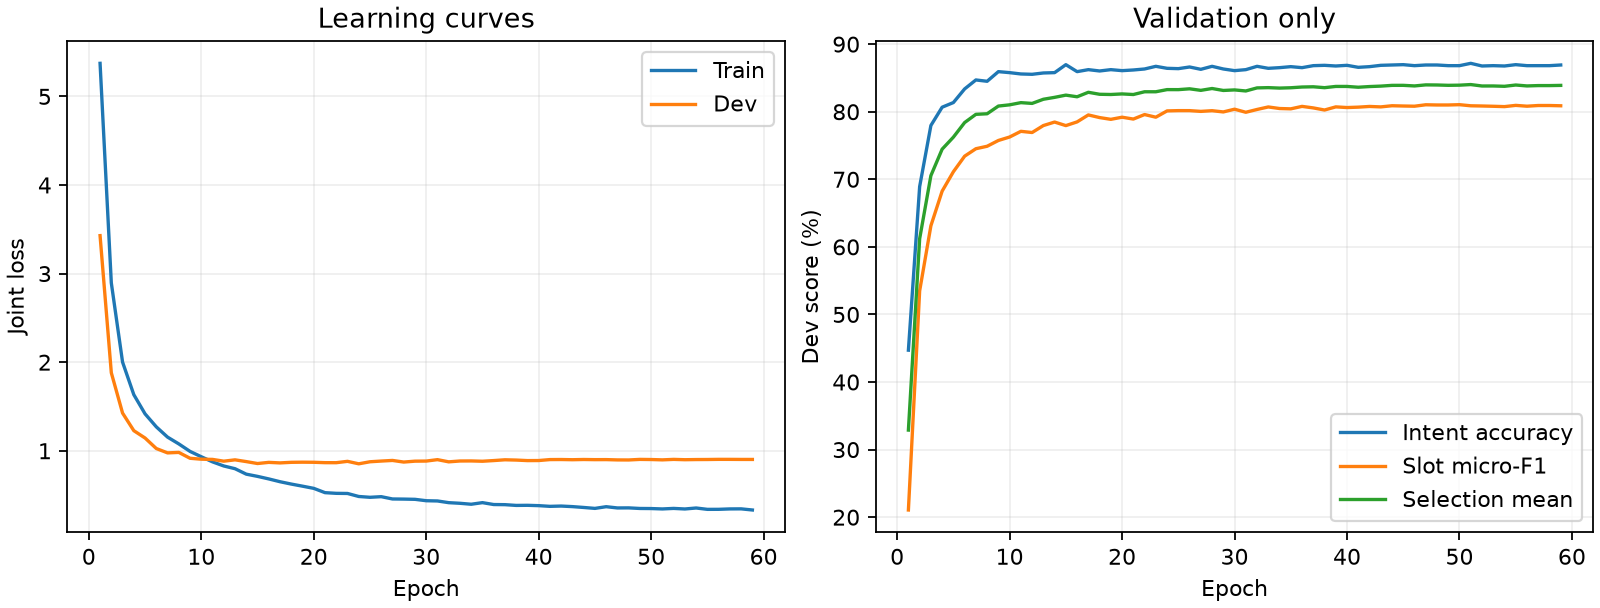

In [42]:
from IPython.display import display, Image
display(Image(filename=str(Path(SETTINGS["run_dir"]) / "learning_curves.png")))


## Raw-text-only inference and Dev error analysis

In [43]:
from src.model.predict import JointPredictor
from src.data.loader import load_massive
predictor = JointPredictor(SETTINGS["checkpoint"])
dev_records = load_massive(DATA)["dev"]
print(json.dumps(predictor.predict([record["utt"] for record in dev_records[:3]]), indent=2))
from scripts.audit_model import audit
diagnostics = audit(SETTINGS["checkpoint"], DATA, Path(SETTINGS["run_dir"]) / "dev_audit.json")
for error in diagnostics["error_cases"][:2]:
    print(json.dumps(error, indent=2))


train: 11514
dev: 2033
test: 2974
Total: 16521
[
  {
    "id": "0",
    "intent": "iot_hue_lightoff",
    "slots": []
  },
  {
    "id": "1",
    "intent": "iot_hue_lightdim",
    "slots": [
      {
        "type": "house_place",
        "start": 22,
        "end": 26,
        "text": "hall"
      }
    ]
  },
  {
    "id": "2",
    "intent": "iot_hue_lightup",
    "slots": [
      {
        "type": "house_place",
        "start": 7,
        "end": 11,
        "text": "room"
      }
    ]
  }
]
train: 11514
dev: 2033
test: 2974
Total: 16521


{
  "split": "dev",
  "checkpoint": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/checkpoints/b_training.pt",
  "metrics": {
    "intent_accuracy_pct": 87.16182980816528,
    "slot_micro_f1_pct": 80.87900985097247,
    "slot_tp": 1601,
    "slot_fp": 346,
    "slot_fn": 411
  },
  "unknown_word_subsets": {
    "has_unknown_word": {
      "examples": 364,
      "intent_accuracy_pct": 75.82417582417582,
      "slot_micro_f1_pct": 64.76190476190476,
      "slot_tp": 238,
      "slot_fp": 100,
      "slot_fn": 159
    },
    "all_known_words": {
      "examples": 1669,
      "intent_accuracy_pct": 89.6345116836429,
      "slot_micro_f1_pct": 84.55334987593052,
      "slot_tp": 1363,
      "slot_fp": 246,
      "slot_fn": 252
    }
  },
  "false_positive_categories": {
    "same_type_overlapping_boundary_error": 101,
    "other_false_positive": 179,
    "correct_boundary_wrong_type": 66
  },
  "raw_illegal_bio_transitions": 2477,
  "decoded_illegal_bio_transit

## Frozen checkpoint reload and final Dev/Test evaluation

The selected checkpoint is reloaded without further training. The current run is frozen before evaluating Test. The tensor fingerprint is compared with the pre-Test selected reference. Different hardware can change training trajectories; this comparison is printed for audit, while exact within-run Dev reload is mandatory. The published run additionally verifies an exact reference-model match. All table values below are computed outputs.

In [44]:
REFERENCE_MODEL_SHA256 = '59f65ef4c5882be579afdca06037b2cd3c4c3b147308cee2502f05e03d692327'
from datetime import datetime
from zoneinfo import ZoneInfo
from src.model.artifacts import model_state_sha256
from src.model.evaluate import evaluate_checkpoint
from src.model.train import write_json
from IPython.display import Markdown

RUN_TEST = True  # Explicit final evaluation after the recorded recipe was frozen.
FINAL_OUTPUT = WORK / "results/b_final"
checkpoint = Path(SETTINGS["checkpoint"])
state = torch.load(checkpoint, map_location="cpu", weights_only=True)["model_state"]
tensor_sha = model_state_sha256(state)
reference_match = tensor_sha == REFERENCE_MODEL_SHA256
print("Exact selected-reference tensor match:", reference_match)
freeze = {
    "frozen_at_sgt": datetime.now(ZoneInfo("Asia/Singapore")).isoformat(),
    "checkpoint": str(checkpoint), "checkpoint_sha256": file_sha256(checkpoint),
    "model_state_sha256": tensor_sha, "reference_model_state_sha256": REFERENCE_MODEL_SHA256,
    "reference_model_match": reference_match, "data_sha256": file_sha256(DATA),
    "training_arguments": SETTINGS, "representative_seed": SETTINGS["seed"],
    "best_epoch": summary["best_epoch"], "epochs_run": summary["epochs_run"],
    "dev_metrics": summary["dev_metrics"],
    "selection_rule": "Mean of Dev intent accuracy and exact-span slot micro-F1",
    "test_used_for_selection": False,
}
write_json(FINAL_OUTPUT / "freeze.json", freeze)
dev_final = evaluate_checkpoint(checkpoint, DATA, "dev", FINAL_OUTPUT / "dev")
assert dev_final["intent_accuracy_pct"] == summary["dev_metrics"]["intent_accuracy_pct"]
assert dev_final["slot_micro_f1_pct"] == summary["dev_metrics"]["slot_micro_f1_pct"]
test_final = evaluate_checkpoint(checkpoint, DATA, "test", FINAL_OUTPUT / "test", frozen=True)
assert file_sha256(checkpoint) == freeze["checkpoint_sha256"]
final_result = {"freeze": freeze, "summary": summary, "dev": dev_final, "test": test_final}
write_json(FINAL_OUTPUT / "final_results.json", final_result)
table = "| Split | Total parameters | Trainable parameters | Intent (%) | Slot micro-F1 (%) | Trained / best epoch |\n|---|---:|---:|---:|---:|---:|\n"
for split, metrics in (("Dev", dev_final), ("Test", test_final)):
    table += f"| {split} | {metrics['parameters']['total']} | {metrics['parameters']['trainable']} | {metrics['intent_accuracy_pct']:.2f} | {metrics['slot_micro_f1_pct']:.2f} | {summary['epochs_run']} / {summary['best_epoch']} |\n"
display(Markdown(table))
print("B_FINAL_RESULT=" + json.dumps({"workspace": str(WORK), **final_result}))


Exact selected-reference tensor match: True
train: 11514
dev: 2033
test: 2974
Total: 16521


{
  "split": "dev",
  "intent_accuracy_pct": 87.16182980816528,
  "slot_micro_f1_pct": 80.87900985097247,
  "slot_tp": 1601,
  "slot_fp": 346,
  "slot_fn": 411,
  "parameters": {
    "total": 907002,
    "trainable": 907002
  },
  "best_epoch": 51,
  "checkpoint": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/checkpoints/b_training.pt",
  "checkpoint_sha256": "1aaa3014264d01fe8ddca85fbde15af7ca6641095a80b0a7ab4ad2e8f286dfda",
  "frozen_for_test": false,
  "num_examples": 2033,
  "torch": "2.9.1"
}
dev: intent=87.16%, slot micro-F1=80.88%
train: 11514
dev: 2033
test: 2974
Total: 16521


{
  "split": "test",
  "intent_accuracy_pct": 86.28110289172831,
  "slot_micro_f1_pct": 78.00875273522976,
  "slot_tp": 2139,
  "slot_fp": 530,
  "slot_fn": 676,
  "parameters": {
    "total": 907002,
    "trainable": 907002
  },
  "best_epoch": 51,
  "checkpoint": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/checkpoints/b_training.pt",
  "checkpoint_sha256": "1aaa3014264d01fe8ddca85fbde15af7ca6641095a80b0a7ab4ad2e8f286dfda",
  "frozen_for_test": true,
  "num_examples": 2974,
  "torch": "2.9.1"
}
test: intent=86.28%, slot micro-F1=78.01%


| Split | Total parameters | Trainable parameters | Intent (%) | Slot micro-F1 (%) | Trained / best epoch |
|---|---:|---:|---:|---:|---:|
| Dev | 907002 | 907002 | 87.16 | 80.88 | 59 / 51 |
| Test | 907002 | 907002 | 86.28 | 78.01 | 59 / 51 |


B_FINAL_RESULT={"workspace": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x", "freeze": {"frozen_at_sgt": "2026-11-02T16:59:34.301046+08:00", "checkpoint": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/checkpoints/b_training.pt", "checkpoint_sha256": "1aaa3014264d01fe8ddca85fbde15af7ca6641095a80b0a7ab4ad2e8f286dfda", "model_state_sha256": "59f65ef4c5882be579afdca06037b2cd3c4c3b147308cee2502f05e03d692327", "reference_model_state_sha256": "59f65ef4c5882be579afdca06037b2cd3c4c3b147308cee2502f05e03d692327", "reference_model_match": true, "data_sha256": "c70f75c6a543a26e249ec383df67733ad9b1066f6c0406c2e04a3f03356e407e", "training_arguments": {"data": "/private/tmp/sc4002-final-b-resources-20261102/data/1.0/data/en-US.jsonl", "run_dir": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/results/b_training", "checkpoint": "/var/folders/p8/r57jqjl13p5_6s2y1_hfv09r0000gn/T/sc4002-b-notebook-p0rrbn3x/checkpoin